# Philippine Earthquake Analysis

Describe historical earthquake locations, magnitudes, depths, and counts. Fault/trench maps provide geographic context. Descriptive statistics and EDA are primary; the GMM extension follows the EDA, with further ML experiments in the appendix. Complete interpretation prompts using executed results.


**New ML section:** [Jump to the new ML extension](#ml-extension) — magnitude–depth profiles, geographic maps, and robustness checks. It appears immediately before Appendix A. Search for **Look beneath the map** if your viewer does not follow notebook links.

## 1. Dataset description

Complete after loading and checking the source.

- **1.1 Name:** Philippine Earthquakes (1900-2025)
- **1.2 Source:** USGS records distributed through Kaggle; verify the dataset documentation.
- **1.3 URL:** https://www.kaggle.com/datasets/bwandowando/philippine-earthquakes-1900-2025-from-usgs

Record the download date, resolved dataset path/version, and actual date coverage. Do not infer coverage from the dataset title.

## 2.1 Libraries

Group imports once so dependencies are visible and later cells focus on their questions. pandas/NumPy support tabular analysis; Matplotlib/seaborn create charts; GeoPandas/Shapely support map geometry and CRS conversion. Standard-library utilities handle paths, downloads, archives, and source records.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import urlopen
from urllib.parse import urlencode
import json
import zipfile

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from matplotlib.lines import Line2D
import seaborn as sns
import geopandas as gpd
from shapely.geometry import box

import html
import matplotlib.patheffects as pe
import folium
from folium.plugins import HeatMap, FastMarkerCluster


C:\Users\Jacob\Documents\Codex\2026-11-07\und\work\earthquake-validation\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Shared configuration and plotting helpers

Run setup once before question cells. Centralize repeated labels, map styling, and image saving to avoid inconsistent copies. Grid size and magnitude cutoffs are explicit analysis choices; they are not empirically optimized settings.


In [2]:
reference_dir = Path("data/reference")
output_dir = Path("outputs")
reference_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(exist_ok=True)
GRID_SIZE_M = 50_000
STRONG_MAG = 6.0
VERY_STRONG_MAG = 7.0
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11})

def coverage(frame):
    dates = frame["time"].dropna()
    period = f"{dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d} UTC" if len(dates) else "No dated records"
    return f"n={len(frame):,} | {period} | missing dates={frame['time'].isna().sum():,}"

def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(output_dir / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def map_base(ax, bounds):
    west, south, east, north = bounds
    if not land.empty:
        visible = land.cx[west:east, south:north]
        if not visible.empty:
            visible.plot(ax=ax, color="#f1eddf", edgecolor="#66736f", linewidth=0.5)
        ax.set_facecolor("#e4f0f7")
    else:
        ax.set_facecolor("#f4f4f4")
        ax.text(0.02, 0.02, "Coastline unavailable", transform=ax.transAxes, fontsize=8)
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect(1 / np.cos(np.deg2rad((south+north)/2)))
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    ax.grid(alpha=0.15, linestyle=":")

TECTONIC_COLORS = {"Active faults":"#a71930", "Trenches":"#073e87", "Collision zones":"#704080"}

def draw_tectonics(ax, view):
    west,south,east,north = view
    for name,layer in layers.items():
        visible=layer.cx[west:east,south:north]
        for approximate,group in visible.groupby("approximate"):
            if not group.empty:
                group.plot(ax=ax,color=TECTONIC_COLORS[name],linewidth=1.5,zorder=8,
                           linestyle="--" if approximate or name=="Trenches" else "-",
                           path_effects=[pe.Stroke(linewidth=3,foreground="white"),pe.Normal()])
    if not layers:
        ax.text(.5,.95,"TECTONIC OVERLAY UNAVAILABLE",transform=ax.transAxes,ha="center",va="top",
                color="#a71930",weight="bold",bbox={"facecolor":"white","edgecolor":"#a71930"})

def tectonic_handles():
    h=[Line2D([],[],color=TECTONIC_COLORS[name],lw=2,linestyle="--" if name=="Trenches" else "-",label=name) for name in layers]
    if layers:h.append(Line2D([],[],color="#555",linestyle="--",label="Dashed: approximate trace / trench"))
    return h

def tectonic_caption(fig):
    fig.text(.02,-.025,tectonic_note+"\nSource: "+TECTONIC_URL,fontsize=7,va="top")


## 2.2 Data acquisition

KaggleHub reuses its cache, but an unversioned handle may resolve to a newer release. Record the resolved version, retrieval date, and actual coverage for the final export. Fail visibly on acquisition errors rather than substituting a different dataset.


In [3]:
DATASET_HANDLE = "bwandowando/philippine-earthquakes-1900-2025-from-usgs"

try:
    path = kagglehub.dataset_download(DATASET_HANDLE)
except Exception as exc:
    raise RuntimeError(
        "Dataset download failed. Check internet access and any Kaggle access requirements."
    ) from exc

print("Path to dataset files:", path)
dataset_dir = Path(path)
csv_files = sorted(dataset_dir.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {dataset_dir}")

for csv_path in csv_files:
    print(csv_path.relative_to(dataset_dir))


Path to dataset files: C:\Users\Jacob\.cache\kagglehub\datasets\bwandowando\philippine-earthquakes-1900-2025-from-usgs\versions\74
Philippine_Earthquakes_USGS.csv


Select the CSV below if the download contains more than one. Keep `df_raw` unchanged; use `df` for your work.

In [4]:
CSV_FILENAME = None  # Set a relative filename from the printed list if needed.

if CSV_FILENAME is None:
    if len(csv_files) != 1:
        raise ValueError("Multiple CSV files found. Set CSV_FILENAME to one printed above.")
    selected_csv = csv_files[0]
else:
    selected_csv = dataset_dir / CSV_FILENAME
    if selected_csv.resolve() not in {p.resolve() for p in csv_files}:
        raise ValueError("CSV_FILENAME must identify a CSV from the downloaded dataset.")

try:
    df_raw = pd.read_csv(selected_csv)
except (OSError, UnicodeError, pd.errors.ParserError, pd.errors.EmptyDataError) as exc:
    raise RuntimeError(f"Could not load CSV: {selected_csv}") from exc

df = df_raw.copy(deep=True)
print("Loaded:", selected_csv.name)
print("Rows and columns:", df_raw.shape)


Loaded: Philippine_Earthquakes_USGS.csv
Rows and columns: (27736, 29)


### Geographic resources

All maps share one loaded set of tectonic geometries. The recovered ArcGIS layer is published by **aechanes_geodata**; original authority and mapping date are unspecified. It is a **provisional third-party reference**, not a verified current PHIVOLCS map.

The loader reports actual counts and missing geometries. Missing lines cannot be reconstructed from their names. Layer coverage is narrower than the earthquake catalog.


In [5]:
LAND_URL="https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip"
TECTONIC_URL="https://services.arcgis.com/eSGO1QW0lYo90eNU/arcgis/rest/services/ActiveFaultTrenches/FeatureServer/0"
TECTONIC_ITEM="https://www.arcgis.com/sharing/rest/content/items/e4b2bc9b68254609b5965b16163eba3b?f=json"

def read_json_url(url):
    with urlopen(url,timeout=30) as response:result=json.load(response)
    if "error" in result:raise ValueError(str(result["error"]))
    return result

def load_tectonics(directory):
    cache=directory/"arcgis_active_fault_trenches.geojson"
    provenance_path=cache.with_suffix(".source.json")
    if not cache.exists():
        metadata=read_json_url(TECTONIC_URL+"?f=json")
        item=read_json_url(TECTONIC_ITEM)
        if metadata.get("geometryType")!="esriGeometryPolyline" or item.get("owner")!="aechanes_geodata":
            raise ValueError("Unexpected source identity or geometry type.")
        ids=read_json_url(TECTONIC_URL+"/query?"+urlencode({"where":"1=1","returnIdsOnly":"true","f":"json"}))["objectIds"]
        features=[]
        for start in range(0,len(ids),100):
            query={"objectIds":','.join(map(str,ids[start:start+100])),"outFields":"*","outSR":4326,"f":"geojson"}
            batch=read_json_url(TECTONIC_URL+"/query?"+urlencode(query))
            if batch.get("exceededTransferLimit"):raise ValueError("Truncated response.")
            features.extend(batch["features"])
        returned=[f["properties"][metadata["objectIdField"]] for f in features]
        if set(returned)!=set(ids) or len(returned)!=len(ids):raise ValueError("Missing or duplicated source records.")
        provenance={"source_url":TECTONIC_URL,"publisher":item["owner"],"original_authority":"Unspecified",
                    "mapping_date":"Unspecified","retrieved_utc":datetime.now(timezone.utc).isoformat(),
                    "source_records":len(ids),"item_metadata":item,"layer_metadata":metadata}
        cache.write_text(json.dumps({"type":"FeatureCollection","features":features}),encoding="utf-8")
        provenance_path.write_text(json.dumps(provenance,indent=2),encoding="utf-8")
    if not provenance_path.exists():raise ValueError("Cached geometry has no provenance; recover its source before plotting.")
    provenance=json.loads(provenance_path.read_text(encoding="utf-8"))
    if provenance.get("source_url","").replace("http:","https:")!=TECTONIC_URL:raise ValueError("Cache source URL does not match.")
    resource=json.loads(cache.read_text(encoding="utf-8"))
    if len(resource["features"])!=provenance.get("source_records"):raise ValueError("Cached/source feature counts differ.")
    frame=gpd.read_file(cache)
    if frame.crs is None:raise ValueError("Missing source CRS.")
    frame=frame.to_crs("EPSG:4326")
    missing=frame.geometry.isna()|frame.geometry.is_empty
    missing_names=frame.loc[missing,"NAME"].fillna("Unnamed").tolist()
    usable=frame.loc[~missing].copy()
    if usable.empty or not usable.geom_type.isin(["LineString","MultiLineString"]).all() or not usable.is_valid.all():
        raise ValueError("Invalid, empty, or non-line geometry.")
    xmin,ymin,xmax,ymax=usable.total_bounds
    if not(110<xmin<xmax<140 and 0<ymin<ymax<30):raise ValueError("Unexpected extent; review coordinates and CRS.")
    description=usable.DESC_.fillna("").str.lower()
    known={"trace approximate","active fault","approximate offshore projection","trench","collision zone","transform fault"}
    if not set(description).issubset(known):raise ValueError("Unknown descriptions; review feature classification.")
    usable["approximate"]=description.str.contains("approximate")
    usable["layer"]=np.select([description.eq("trench"),description.eq("collision zone")],["Trenches","Collision zones"],default="Active faults")
    status={"source_records":len(frame),"usable_geometries":len(usable),"missing_geometry_names":missing_names,
            "extent_lon_lat":usable.total_bounds.tolist(),**{k:provenance[k] for k in ["publisher","original_authority","mapping_date","retrieved_utc"]}}
    return {name:group.copy() for name,group in usable.groupby("layer")},status

land=gpd.GeoDataFrame(geometry=[],crs="EPSG:4326")
land_path=reference_dir/"ne_50m_land.zip"
try:
    if not land_path.exists():
        with urlopen(LAND_URL,timeout=30) as response:content=response.read()
        import io
        if not zipfile.is_zipfile(io.BytesIO(content)):raise ValueError("Coastline response is not a ZIP.")
        land_path.write_bytes(content)
        land_path.with_suffix(".source.json").write_text(json.dumps({"source_url":LAND_URL,"retrieved_utc":datetime.now(timezone.utc).isoformat(),"scale":"1:50 million"}),encoding="utf-8")
    land=gpd.read_file(f"zip://{land_path.resolve()}").to_crs("EPSG:4326")
except Exception as exc:print("Coastline unavailable:",exc)

layers,tectonic_status={},{}
try:
    layers,tectonic_status=load_tectonics(reference_dir)
    missing_names=tectonic_status["missing_geometry_names"]
    tectonic_note="Provisional reference: aechanes_geodata; original authority and mapping date unspecified."
    if missing_names:tectonic_note+=" INCOMPLETE: no geometry for "+", ".join(missing_names)+"."
    display(pd.DataFrame([tectonic_status]))
except Exception as exc:tectonic_note="TECTONIC OVERLAY UNAVAILABLE: "+str(exc)
print(tectonic_note)


,source_records,usable_geometries,missing_geometry_names,extent_lon_lat,publisher,original_authority,mapping_date,retrieved_utc
0,175,174,[Sulu Trench],"[118.98867, 4.966208, 127.933293, 20.486447]",aechanes_geodata,Unspecified,Unspecified,2026-11-11T10:53:27.529401+00:00


Provisional reference: aechanes_geodata; original authority and mapping date unspecified. INCOMPLETE: no geometry for Sulu Trench.


## 2.3.1 Data cleaning

Preserve `df_raw`, document conversion failures and event revisions, then prepare question-specific subsets. A global complete-case filter would discard geographically useful events merely because another measurement is missing. Retain reporting fields in `df` even when the core analysis does not use them.


In [6]:
df = df_raw.copy(deep=True).reset_index(drop=True)
display(df.dtypes)

for column in ["time", "updated"]:
    original = df[column].copy()
    df[column] = pd.to_datetime(original, format="mixed", errors="coerce", utc=True)
    failed = original.notna() & df[column].isna()
    print(f"{column}: {failed.sum()} failed conversions")
    display(df_raw.loc[failed.to_numpy(), ["id", column]])
for column in ["latitude", "longitude", "depth", "mag", "tsunami"]:
    df[column] = pd.to_numeric(df[column], errors="coerce").replace([np.inf, -np.inf], np.nan)

repeated = df["id"].notna() & df["id"].duplicated(keep=False)
duplicate_audit = df.loc[repeated].copy()
remove_indices = []
for event_id, group in duplicate_audit.groupby("id", sort=False):
    if group["updated"].isna().any():
        raise ValueError(f"Review duplicate ID {event_id}: missing update time.")
    latest = group.loc[group["updated"].eq(group["updated"].max())]
    if len(latest.drop_duplicates()) > 1:
        raise ValueError(f"Review duplicate ID {event_id}: conflicting latest revisions.")
    remove_indices.extend(group.index[group.index != latest.index[0]])
df = df.drop(index=remove_indices).copy()
print("Older/repeated revisions removed:", len(remove_indices), "| Retained:", len(df))
core = ["id", "time", "latitude", "longitude", "depth", "mag", "magType", "place"]
df_core = df[core].copy()
display(df_core.describe(include="all"))


id                   str
mag              float64
place                str
time                 str
updated              str
tz               float64
url                  str
felt             float64
cdi              float64
mmi              float64
alert                str
status               str
tsunami            int64
sig                int64
net                  str
code                 str
ids                  str
sources              str
types                str
nst              float64
dmin             float64
rms              float64
gap              float64
magType              str
type_property        str
title                str
longitude        float64
latitude         float64
depth            float64
dtype: object

time: 0 failed conversions


,id,time


updated: 0 failed conversions


,id,updated


Older/repeated revisions removed: 80 | Retained: 27656


,id,time,latitude,longitude,depth,mag,magType,place
count,27656,27656,27656.000000,27656.000000,27654.000000,26470.000000,26025,27656
unique,27656,NaN,NaN,NaN,NaN,NaN,10,18127
top,us7000twur,NaN,NaN,NaN,NaN,NaN,mb,"Mindanao, Philippines"
freq,1,NaN,NaN,NaN,NaN,NaN,23191,210
mean,NaN,2004-07-27 18:28:17.783819+00:00,9.988791,124.634311,69.811276,4.572465,NaN,NaN
min,NaN,1901-12-15 06:57:00+00:00,2.241600,115.847000,0.700000,0.000000,NaN,NaN
25%,NaN,1995-04-30 05:21:42.035000+00:00,6.012825,122.509750,33.000000,4.300000,NaN,NaN
50%,NaN,2007-04-21 09:32:59.795000+00:00,9.307000,125.658450,35.000000,4.500000,NaN,NaN
75%,NaN,2019-02-09 00:11:03.517500+00:00,13.173000,126.547000,73.900000,4.800000,NaN,NaN
max,NaN,2026-11-08 07:25:35.852000+00:00,24.938000,135.439000,678.000000,8.300000,NaN,NaN


### 2.3.1.1 Missing values

Check missing values and record exclusions separately for each analysis. Retain records that can still answer other questions.


In [7]:
display(pd.DataFrame({"missing_count": df_core.isna().sum(),
                      "missing_pct": df_core.isna().mean().mul(100).round(2)}))

valid_coordinates = df.latitude.between(-90, 90) & df.longitude.between(-180, 180)
df_geo = df.loc[valid_coordinates].copy()
df_frequency = df.dropna(subset=["time", "mag"]).copy()
df_frequency["year"] = df_frequency.time.dt.year
df_depth_mag = df.dropna(subset=["depth", "mag"]).copy()
df_tsunami = df_geo.copy()

display(pd.DataFrame([
    {"subset": name, "retained": len(subset), "excluded": len(df)-len(subset)}
    for name, subset in [("Geographic",df_geo),("Frequency",df_frequency),
                         ("Depth–magnitude",df_depth_mag),("Tsunami map",df_tsunami)]
]))


,missing_count,missing_pct
id,0,0.00
time,0,0.00
latitude,0,0.00
longitude,0,0.00
depth,2,0.01
mag,1186,4.29
magType,1631,5.90
place,0,0.00


,subset,retained,excluded
0,Geographic,27656,0
1,Frequency,26470,1186
2,Depth–magnitude,26468,1188
3,Tsunami map,27656,0


### 2.3.1.2 Outliers and validity

Inspect unusual values and distinguish valid extremes from invalid records. Check magnitude and depth for central tendency, spread, and potential outliers. IQR flags identify records for review; they do not justify automatic removal.


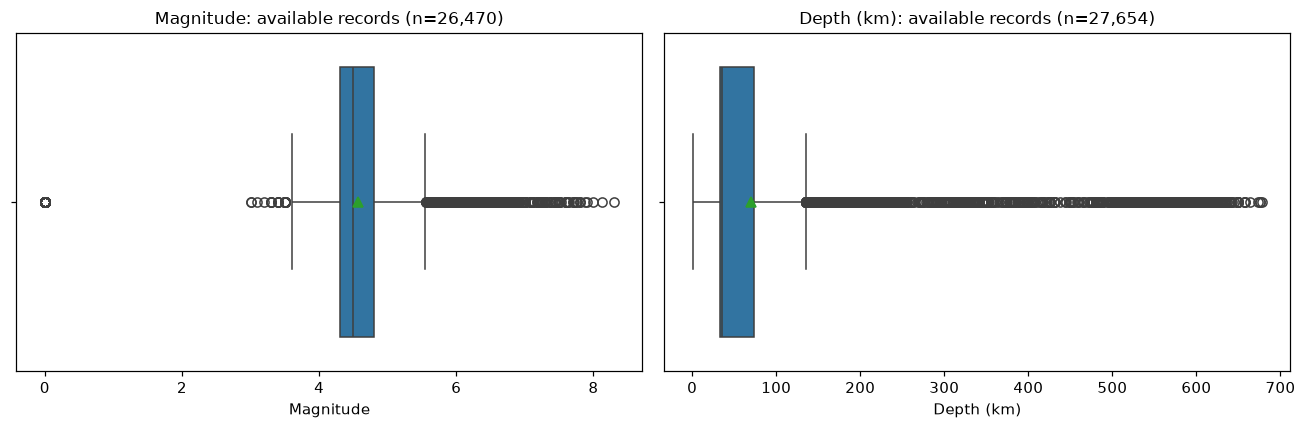

,column,lower_bound,upper_bound,potential_outliers
0,mag,3.55,5.55,1949
1,depth,-28.35,135.25,2763


,id,time,latitude,longitude,depth,mag,magType,place
11634,usp000hktr,2010-09-16 19:47:47.150+00:00,8.242,122.619,44.9,0.0,NaN,"14 km NNW of Liloy, Philippines"
11869,usp000h764,2010-02-11 17:29:24.590+00:00,10.129,125.497,10.0,0.0,NaN,"21 km NNW of Dinagat, Philippines"
12642,usp000gr77,2008-12-23 02:50:13.150+00:00,5.164,125.688,109.3,0.0,NaN,"36 km SE of Sarangani, Philippines"
12644,usp000gr2n,2008-12-21 11:03:15.660+00:00,21.059,122.233,149.4,0.0,NaN,"72 km NNE of Basco, Philippines"
12666,usp000gq0a,2008-12-06 07:34:30.780+00:00,13.293,120.687,35.0,0.0,NaN,"5 km SSE of Cabacao, Philippines"
...,...,...,...,...,...,...,...,...
16250,usp000brv4,2003-03-03 13:01:04.120+00:00,13.348,120.638,10.0,0.0,NaN,"2 km WNW of Cabacao, Philippines"
16251,usp000bru9,2003-03-03 06:49:32.070+00:00,6.682,123.708,33.0,0.0,NaN,"36 km W of Taguisa, Philippines"
16256,usp000brqj,2003-03-01 16:58:16.580+00:00,12.440,123.978,10.0,0.0,NaN,"17 km S of Quezon, Philippines"
16257,usp000brqb,2003-03-01 14:38:59.670+00:00,5.223,126.257,70.8,0.0,NaN,"90 km ESE of Sarangani, Philippines"


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, label, ax in zip(
    ["mag", "depth"], ["Magnitude", "Depth (km)"], axes
):
    sns.boxplot(x=df_core[column].dropna(), showmeans=True, ax=ax)
    ax.set_xlabel(label)
    ax.set_title(f"{label}: available records (n={df_core[column].notna().sum():,})")
plt.tight_layout()
plt.show()

outlier_summary = []
for column in ["mag", "depth"]:
    values = df_core[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_summary.append({
        "column": column,
        "lower_bound": lower,
        "upper_bound": upper,
        "potential_outliers": int(((values < lower) | (values > upper)).sum())
    })
display(pd.DataFrame(outlier_summary))

display(df_core.loc[df_core["mag"].le(0)])


### 2.3.1.3 Data types and derived fields

Use UTC consistently, inspect actual date coverage, and check coordinate ranges before mapping. Count years from parsed dates rather than source titles. Mixed magnitude methods remain visible because they can affect comparisons.


In [9]:
print("Missing or invalid coordinates:", int((~valid_coordinates).sum()))
display(df.loc[~valid_coordinates, ["id", "latitude", "longitude"]])
print("Earliest date (UTC):", df.time.min())
print("Latest date (UTC):", df.time.max())
display(df.magType.value_counts(dropna=False))


Missing or invalid coordinates: 0


,id,latitude,longitude


Earliest date (UTC): 1901-12-15 06:57:00+00:00
Latest date (UTC): 2026-11-08 07:25:35.852000+00:00


magType
mb     23191
NaN     1631
mw      1058
mwc      847
mww      634
ms       169
mwb      107
mwr       10
m          7
Mb         1
mB         1
Name: count, dtype: int64

### Duplicate review

Repeated IDs can represent revised solutions for the same event. Retain the latest documented update, and stop for review when that choice is ambiguous. Measurement matches across different IDs are candidates for inspection, not automatic deletion rules.


In [10]:
print("Source rows with repeated event IDs:", len(duplicate_audit))
display(duplicate_audit.sort_values(["id", "updated"]))

fields = ["time", "latitude", "longitude", "depth", "mag"]
complete = df.dropna(subset=fields)
display(complete.loc[complete.duplicated(subset=fields, keep=False), ["id"]+fields])


Source rows with repeated event IDs: 160


,id,mag,place,time,updated,tz,url,felt,cdi,mmi,...,nst,dmin,rms,gap,magType,type_property,title,longitude,latitude,depth
1549,us6000rc62,4.6,"48 km NNE of Namuac, Philippines",2025-09-23 04:33:01.276+00:00,2025-09-23 05:00:52.040+00:00,NaN,https://earthquake.usgs.gov/earthquakes/eventp...,NaN,NaN,NaN,...,52.0,3.802,0.82,120.0,mb,earthquake,"M 4.6 - 48 km NNE of Namuac, Philippines",121.3677,19.0053,53.088
1550,us6000rc62,4.6,"52 km NNE of Namuac, Philippines",2025-09-23 04:33:00.465+00:00,2025-12-07 00:00:08.040+00:00,NaN,https://earthquake.usgs.gov/earthquakes/eventp...,NaN,NaN,NaN,...,63.0,3.790,0.79,120.0,mb,earthquake,"M 4.6 - 52 km NNE of Namuac, Philippines",121.4160,19.0218,45.416
1544,us6000rcyr,4.6,"18 km NNE of Cabatuan, Philippines",2025-09-26 06:48:09.299+00:00,2025-09-26 07:21:56.040+00:00,NaN,https://earthquake.usgs.gov/earthquakes/eventp...,NaN,NaN,NaN,...,49.0,10.836,0.69,125.0,mb,earthquake,"M 4.6 - 18 km NNE of Cabatuan, Philippines",125.2592,12.6814,35.000
1545,us6000rcyr,4.6,"19 km NNE of Cabatuan, Philippines",2025-09-26 06:48:09.212+00:00,2025-12-12 05:40:47.040+00:00,NaN,https://earthquake.usgs.gov/earthquakes/eventp...,NaN,NaN,NaN,...,56.0,10.846,0.55,122.0,mb,earthquake,"M 4.6 - 19 km NNE of Cabatuan, Philippines",125.2951,12.6852,35.000
1587,us6000rd5k,4.3,"14 km NE of Cagdianao, Philippines",2025-09-04 03:55:38.499+00:00,2025-09-29 04:29:30.040+00:00,NaN,https://earthquake.usgs.gov/earthquakes/eventp...,NaN,NaN,NaN,...,34.0,2.932,0.59,121.0,mb,earthquake,"M 4.3 - 14 km NE of Cagdianao, Philippines",125.7639,10.0152,72.042
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1558,us7000qx2y,5.4,"38 km WNW of Bacnotan, Philippines",2025-09-19 03:52:10.415+00:00,2025-12-07 00:00:20.040+00:00,NaN,https://earthquake.usgs.gov/earthquakes/eventp...,15.0,4.8,4.42,...,87.0,6.005,0.85,46.0,mb,earthquake,"M 5.4 - 38 km WNW of Bacnotan, Philippines",120.0268,16.8635,35.000
1555,us7000qxi5,4.8,"227 km SE of Sarangani, Philippines",2025-09-20 10:39:48.869+00:00,2025-09-20 11:13:12.040+00:00,NaN,https://earthquake.usgs.gov/earthquakes/eventp...,NaN,NaN,NaN,...,34.0,1.588,0.84,71.0,mb,earthquake,"M 4.8 - 227 km SE of Sarangani, Philippines",126.8040,3.8460,41.012
1556,us7000qxi5,4.8,"237 km SE of Sarangani, Philippines",2025-09-20 10:39:48.066+00:00,2025-12-07 00:00:24.040+00:00,NaN,https://earthquake.usgs.gov/earthquakes/eventp...,NaN,NaN,NaN,...,37.0,1.665,1.24,71.0,mb,earthquake,"M 4.8 - 237 km SE of Sarangani, Philippines",126.8317,3.7501,35.171
1552,us7000qxl8,4.4,"138 km SSW of Maitum, Philippines",2025-09-21 02:54:35.244+00:00,2025-09-21 03:23:50.040+00:00,NaN,https://earthquake.usgs.gov/earthquakes/eventp...,NaN,NaN,NaN,...,45.0,1.450,0.96,60.0,mb,earthquake,"M 4.4 - 138 km SSW of Maitum, Philippines",124.0314,4.8776,456.318


,id,time,latitude,longitude,depth,mag


## 2.3.2 Exploration

Inspect zero magnitudes, common depths, measurement types, and coverage before interpretation. Preserve valid extremes. Catalog completeness varies over time and location; choosing a modern-period subset alone does not demonstrate completeness.


In [11]:
print("Zero magnitudes:", int(df.mag.eq(0).sum()))
display(df.loc[df.mag.eq(0), ["id", "time", "mag", "magType"]])
display(df[["mag", "depth"]].describe())

if df_geo.empty:
    raise ValueError("No valid coordinates are available for the geographic questions.")
bounds = (df_geo.longitude.min()-1, df_geo.latitude.min()-1,
          df_geo.longitude.max()+1, df_geo.latitude.max()+1)


Zero magnitudes: 445


,id,time,mag,magType
11634,usp000hktr,2010-09-16 19:47:47.150+00:00,0.0,NaN
11869,usp000h764,2010-02-11 17:29:24.590+00:00,0.0,NaN
12642,usp000gr77,2008-12-23 02:50:13.150+00:00,0.0,NaN
12644,usp000gr2n,2008-12-21 11:03:15.660+00:00,0.0,NaN
12666,usp000gq0a,2008-12-06 07:34:30.780+00:00,0.0,NaN
...,...,...,...,...
16250,usp000brv4,2003-03-03 13:01:04.120+00:00,0.0,NaN
16251,usp000bru9,2003-03-03 06:49:32.070+00:00,0.0,NaN
16256,usp000brqj,2003-03-01 16:58:16.580+00:00,0.0,NaN
16257,usp000brqb,2003-03-01 14:38:59.670+00:00,0.0,NaN


,mag,depth
count,26470.000000,27654.000000
mean,4.572465,69.811276
std,0.774878,99.680590
min,0.000000,0.700000
25%,4.300000,33.000000
50%,4.500000,35.000000
75%,4.800000,73.900000
max,8.300000,678.000000


## 2.4.1 Visualizations

Run the notebook from the imports through exploration once before running these questions. Charts use the same prepared event catalog, cached resources, and shared plotting helpers.

Map sequence: magnitude and depth overview → equal-area count map → fault/trench context and zoom windows → tsunami-flag comparison. Counts describe the supplied catalog and do not directly measure hazard or risk.


### Q1 Geographic concentrations

**Question:** Where are recorded earthquakes concentrated?

**How to read:** Overview colors show magnitude and depth separately. Darker grid cells contain more records; the color scale is logarithmic. Ranked bars give exact counts.

**Observation:** [Identify the leading cells, counts, and share of mapped records.]

**Meaning and limitation:** These are historical catalog concentrations, including offshore and nearby events; not administrative regions or damage-risk rankings.


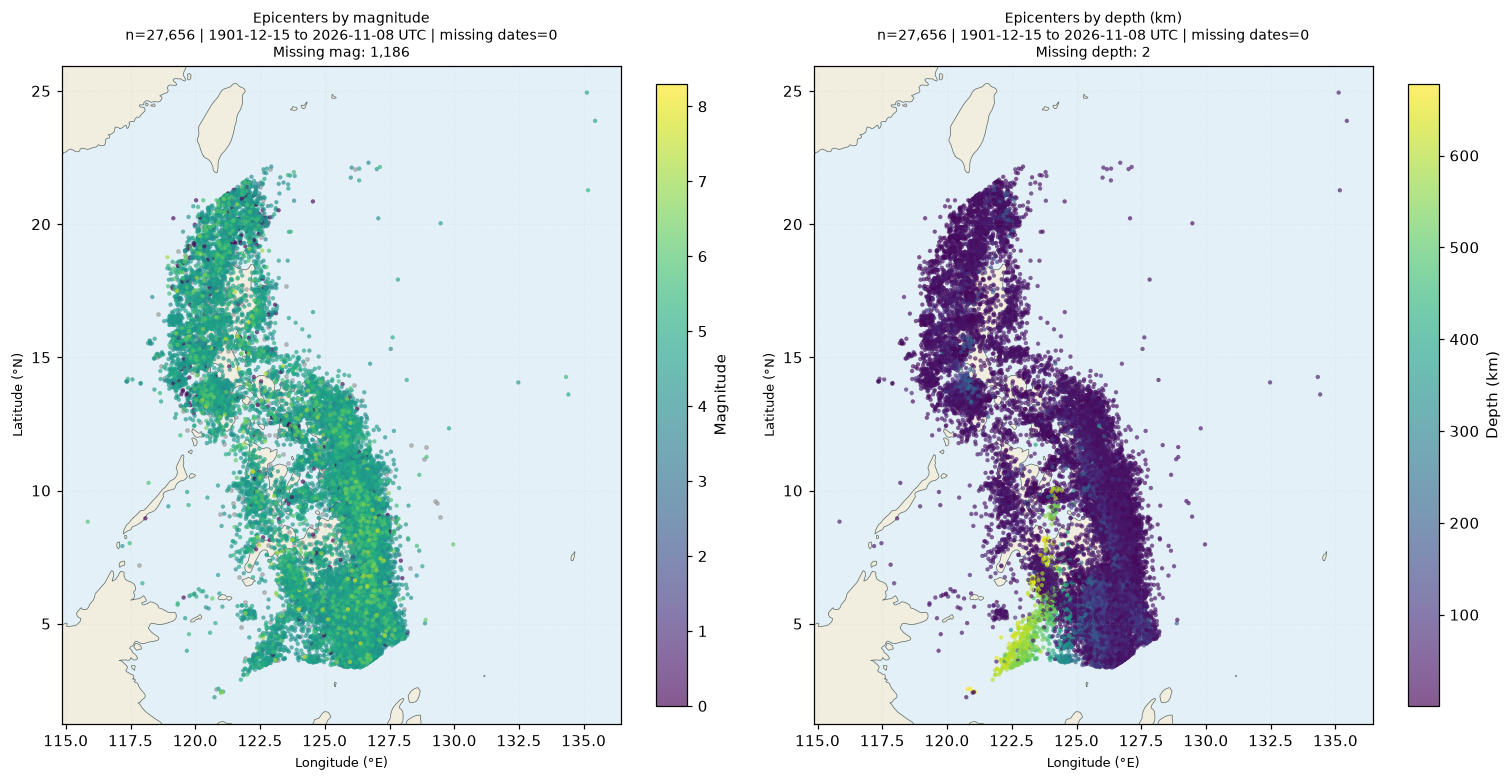

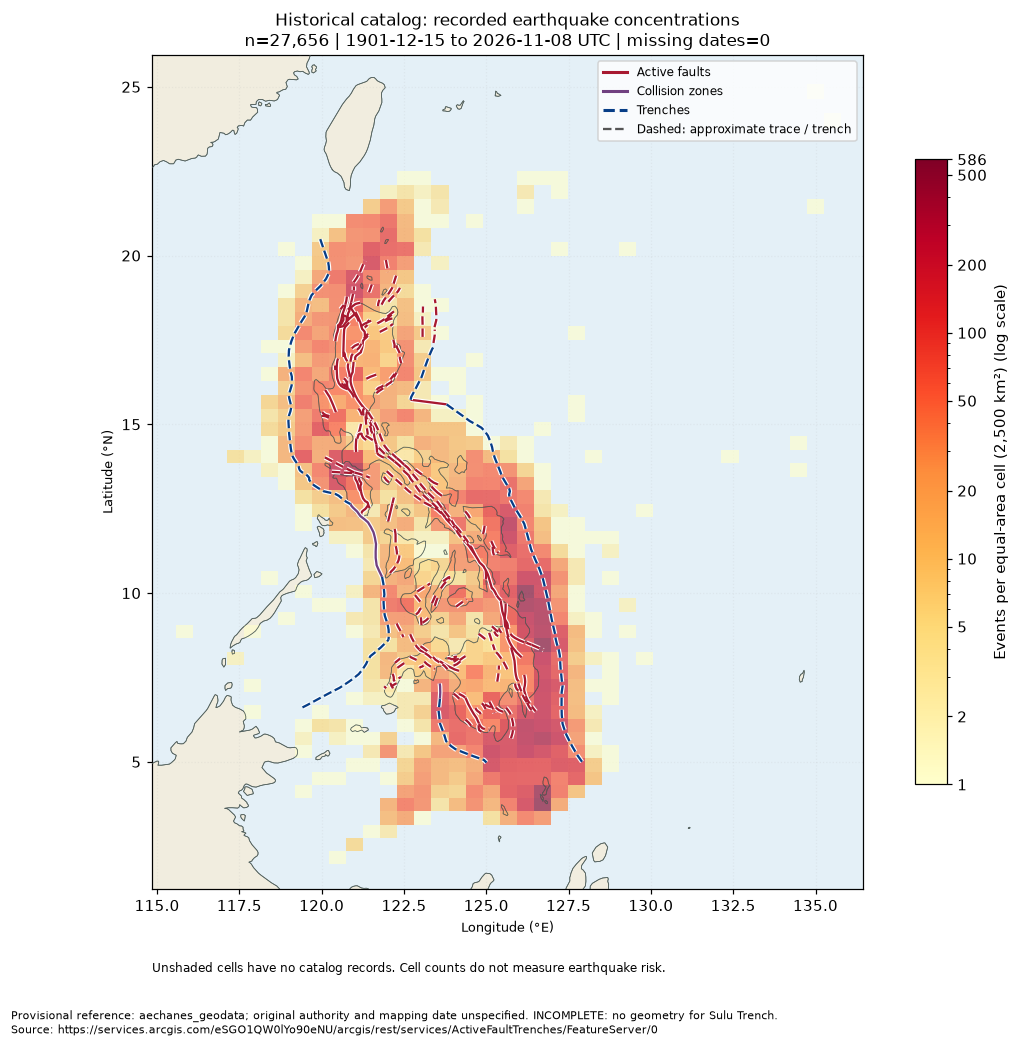

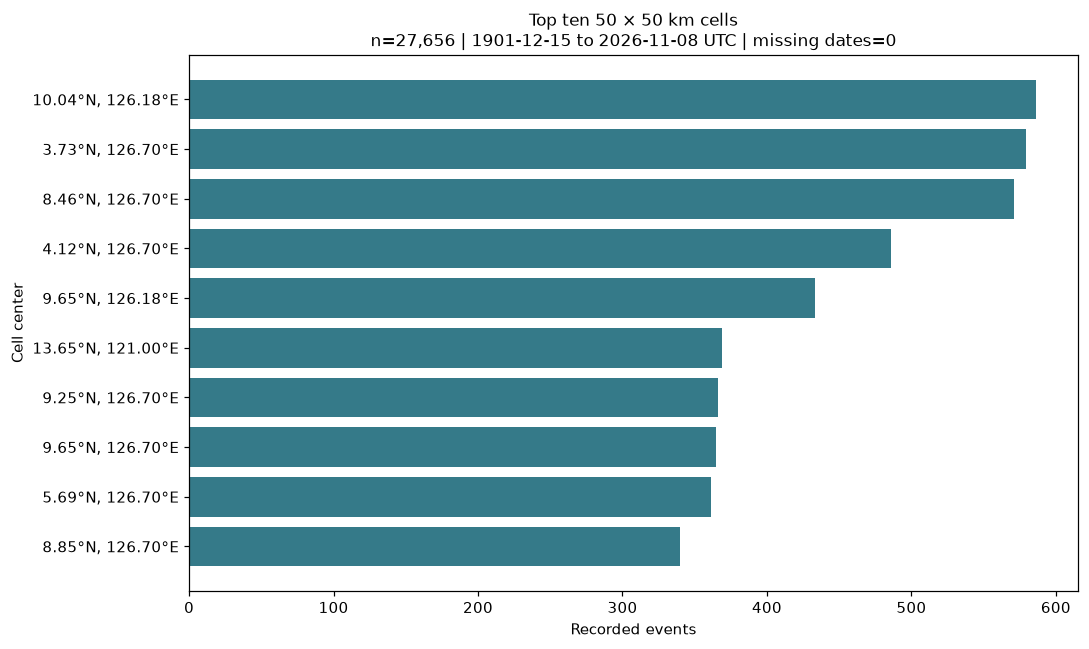

,gx,gy,events,center_lon,center_lat
531,244,22,340,126.701951,8.852710
523,244,14,361,126.701951,5.692117
533,244,24,365,126.701951,9.646631
532,244,23,366,126.701951,9.249452
127,233,34,369,121.001659,13.646950
501,243,24,433,126.183743,9.646631
519,244,10,486,126.701951,4.118733
530,244,21,571,126.701951,8.456383
518,244,9,579,126.701951,3.725905
502,243,25,586,126.183743,10.044266


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9))
for ax, column, label in zip(axes, ["mag", "depth"], ["Magnitude", "Depth (km)"]):
    map_base(ax, bounds)
    missing = df_geo[column].isna()
    ax.scatter(df_geo.loc[missing,"longitude"], df_geo.loc[missing,"latitude"], s=5, color="gray", alpha=0.4)
    measured = df_geo.loc[~missing]
    if len(measured):
        points = ax.scatter(measured.longitude, measured.latitude, c=measured[column],
                            s=8, cmap="viridis", alpha=0.65, linewidths=0)
        fig.colorbar(points, ax=ax, shrink=0.65, label=label)
    ax.set_title(f"Epicenters by {label.lower()}\n{coverage(df_geo)}\nMissing {column}: {missing.sum():,}", fontsize=9)
save_plot(fig, "q1_epicenter_overview")

points = gpd.GeoDataFrame(df_geo.copy(), geometry=gpd.points_from_xy(df_geo.longitude, df_geo.latitude), crs="EPSG:4326").to_crs("EPSG:6933")
points["gx"] = np.floor(points.geometry.x / GRID_SIZE_M).astype(int)
points["gy"] = np.floor(points.geometry.y / GRID_SIZE_M).astype(int)
counts = points.groupby(["gx", "gy"]).size().rename("events").reset_index()
grid = gpd.GeoDataFrame(counts, geometry=[
    box(x*GRID_SIZE_M, y*GRID_SIZE_M, (x+1)*GRID_SIZE_M, (y+1)*GRID_SIZE_M)
    for x,y in zip(counts.gx, counts.gy)], crs="EPSG:6933")
assert grid.events.sum() == len(df_geo)
centers = grid.geometry.centroid.to_crs("EPSG:4326")
grid["center_lon"], grid["center_lat"] = centers.x, centers.y

fig, ax = plt.subplots(figsize=(10, 9))
map_base(ax, bounds)
maximum = int(grid.events.max())
norm = LogNorm(1, maximum) if maximum > 1 else Normalize(0, 1)
grid.to_crs("EPSG:4326").plot(column="events", ax=ax, cmap="YlOrRd", norm=norm, linewidth=0, alpha=.65, zorder=2)
if not land.empty:
    coastline = land.cx[bounds[0]:bounds[2], bounds[1]:bounds[3]]
    if not coastline.empty:
        coastline.boundary.plot(ax=ax, color="#52605d", linewidth=0.5, zorder=3)
bar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="YlOrRd"), ax=ax, shrink=0.75)
ticks = sorted(set([1,maximum]+[x for x in [2,5,10,20,50,100,200,500,1000,2000,5000] if x<=maximum]))
bar.set_ticks(ticks, labels=[f"{x:,}" for x in ticks])
bar.set_label("Events per equal-area cell (2,500 km²)" + (" (log scale)" if maximum>1 else ""))
draw_tectonics(ax,bounds)
if layers:ax.legend(handles=tectonic_handles(),fontsize=8,loc="upper right")
tectonic_caption(fig)
ax.set_title("Historical catalog: recorded earthquake concentrations\n"+coverage(df_geo))
ax.text(0, -0.1, "Unshaded cells have no catalog records. Cell counts do not measure earthquake risk.", transform=ax.transAxes, fontsize=8)
save_plot(fig, "q1_grid_counts")
grid.drop(columns="geometry").to_csv(output_dir/"q1_grid_counts.csv",index=False)

top = grid.sort_values(["events", "gx", "gy"], ascending=[False,True,True]).head(10).sort_values("events")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh([f"{lat:.2f}°N, {lon:.2f}°E" for lat,lon in zip(top.center_lat,top.center_lon)],top.events,color="#357a89")
ax.set_xlabel("Recorded events"); ax.set_ylabel("Cell center")
ax.set_title("Top ten 50 × 50 km cells\n" + coverage(df_geo))
save_plot(fig, "q1_top_cells")
display(top.drop(columns="geometry"))


### Fault and trench mapping

**Question:** How do recorded epicenters relate spatially to mapped tectonic structures?

**How to read:** Start with the reference-only map, then compare the full overlay and fixed close-ups. White outlines keep tectonic lines visible above points.

**Observation:** [Describe alignment and a place where the relationship is less clear.]

**Meaning and limitation:** Proximity does not establish source-fault attribution. The third-party reference is incomplete and its original authority and mapping date are unspecified.


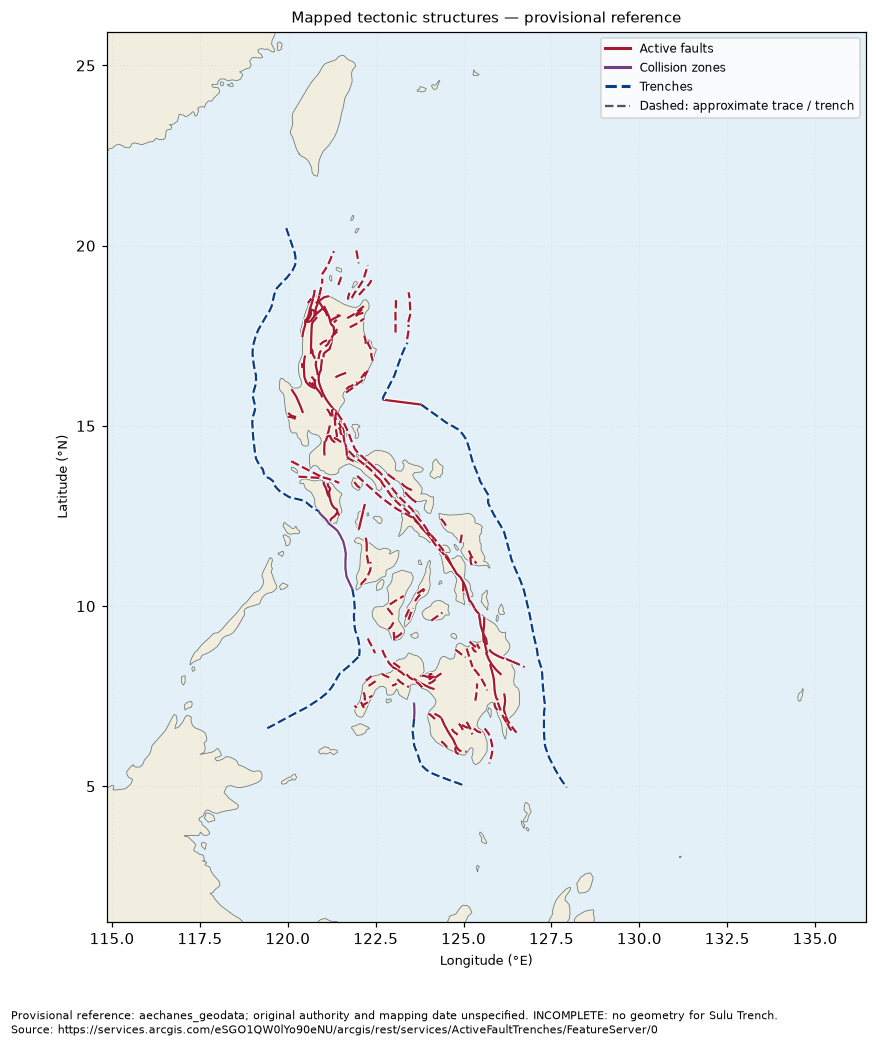

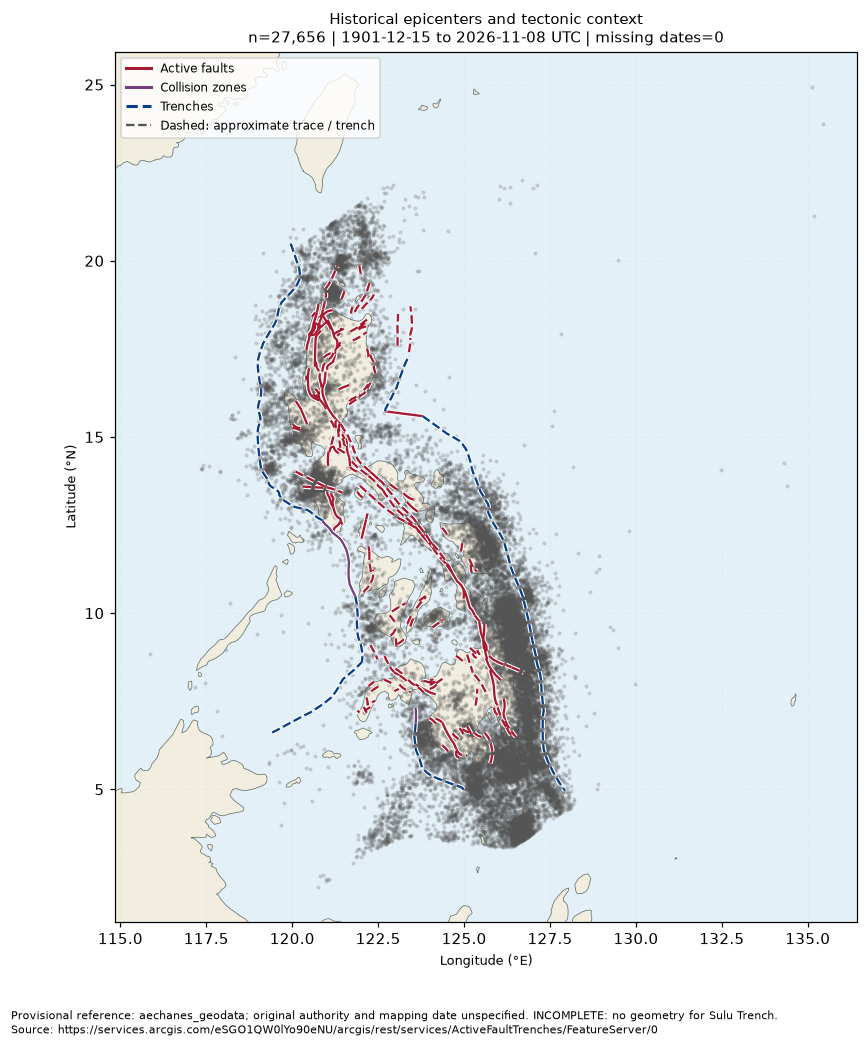

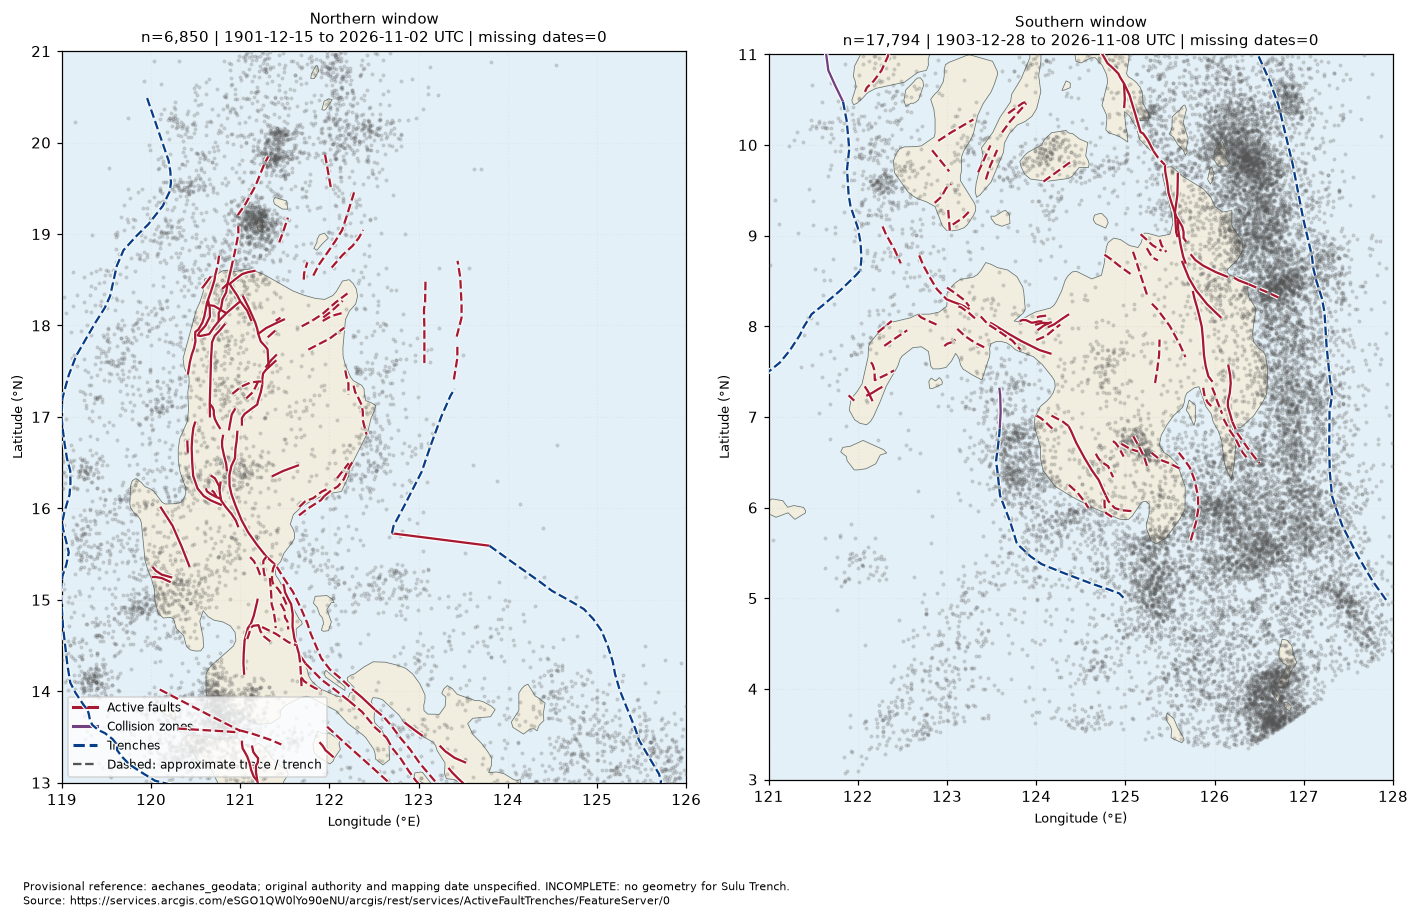

In [13]:
def context_map(title,view,show_events=True,ax=None):
    if ax is None:fig,ax=plt.subplots(figsize=(9,9))
    else:fig=ax.figure
    map_base(ax,view)
    west,south,east,north=view
    subset=df_geo.loc[df_geo.longitude.between(west,east)&df_geo.latitude.between(south,north)]
    if show_events:ax.scatter(subset.longitude,subset.latitude,s=3,color="#555",alpha=.18,zorder=3)
    draw_tectonics(ax,view)
    ax.set_title(title+("\n"+coverage(subset) if show_events else ""),fontsize=10)
    return fig,ax

if layers:
    fig,ax=context_map("Mapped tectonic structures — provisional reference",bounds,False)
    ax.legend(handles=tectonic_handles(),fontsize=8)
    tectonic_caption(fig)
    save_plot(fig,"tectonic_reference_only")
fig,ax=context_map("Historical epicenters and tectonic context" if layers else "Epicenters — overlay unavailable",bounds)
ax.legend(handles=tectonic_handles(),fontsize=8)
tectonic_caption(fig)
save_plot(fig,"q1_tectonic_overlay" if layers else "q1_epicenters_overlay_unavailable")
# Equal geographic spans and panel dimensions support visual comparison.
fig,axes=plt.subplots(1,2,figsize=(13,8))
for ax,(title,view) in zip(axes,[("Northern window",(119,13,126,21)),("Southern window",(121,3,128,11))]):
    context_map(title,view,ax=ax)
axes[0].legend(handles=tectonic_handles(),fontsize=8,loc="lower left")
tectonic_caption(fig)
save_plot(fig,"q1_tectonic_closeups" if layers else "q1_closeups_overlay_unavailable")


### Geographic source register

| Layer | Publisher / source | Mapping date and authority | Coverage |
|---|---|---|---|
| Coastline | Natural Earth, 1:50 million | Generalized reference | Regional orientation, not precise offshore classification |
| [ActiveFaultTrenches](https://www.arcgis.com/home/item.html?id=e4b2bc9b68254609b5965b16163eba3b) | aechanes_geodata | Original authority and mapping date unspecified | Provisional line reference; loader reports usable counts and missing names |

Source URLs, metadata, and retrieval dates are cached beside the files. A service update date is not a geological mapping date. Dashed fault traces are approximate; trenches are blue dashed lines. Collision zones are purple. Missing geometry is never reconstructed.


### Interactive geographic heatmap

**Question:** Where are recorded earthquake locations concentrated at this viewing scale?

**How to read:** Warmer areas contain more recorded locations within the smoothing neighborhood. Every event has equal weight. Toggle heat, epicenters, faults, trenches, and collision zones. Use the static grid table for exact counts.

**Observation:** [Describe main concentrations and compare with the static count map.]

**Meaning and limitation:** Heat is relative concentration, not count, probability, or risk. Smoothing and zoom affect appearance. Online tiles/JavaScript require internet; static PNGs remain available offline.


In [14]:
heat_points=df_geo[["latitude","longitude"]].to_numpy().tolist()
assert len(heat_points)==len(df_geo)==int(grid.events.sum())
m=folium.Map(location=[float(df_geo.latitude.median()),float(df_geo.longitude.median())],tiles=None,zoom_start=5,control_scale=True)
folium.TileLayer("OpenStreetMap",opacity=.65,name="OpenStreetMap (muted)",control=False).add_to(m)
folium.map.CustomPane("tectonic_lines",z_index=650).add_to(m)
heat_group=folium.FeatureGroup(name="Relative concentration of recorded earthquakes",show=True)
HeatMap(heat_points,radius=16,blur=13,min_opacity=.15,max_zoom=10,
        gradient={.2:"#ffffb2",.45:"#fecc5c",.7:"#fd8d3c",1.:"#bd0026"}).add_to(heat_group)
heat_group.add_to(m)
events=folium.FeatureGroup(name="Epicenters (zoom to separate points)",show=False)
FastMarkerCluster(heat_points).add_to(events)
events.add_to(m)
for name,layer in layers.items():
    group=folium.FeatureGroup(name=name+" — provisional reference",show=True)
    folium.GeoJson(json.loads(layer.to_json()),pane="tectonic_lines",control=False,
                   style_function=lambda f:{"color":"white","weight":5,"opacity":.9}).add_to(group)
    color=TECTONIC_COLORS[name]
    folium.GeoJson(json.loads(layer.to_json()),pane="tectonic_lines",
        style_function=lambda f,color=color,name=name:{"color":color,"weight":2.2,"opacity":1,
            "dashArray":"7 4" if f["properties"]["approximate"] or name=="Trenches" else None},
        tooltip=folium.GeoJsonTooltip(fields=["NAME","DESC_"],aliases=["Name","Source description"])).add_to(group)
    group.add_to(m)
heading=("Historical catalog — relative earthquake concentration<br>"+html.escape(coverage(df_geo))
         +"<br>Equal event weights; smoothing and zoom change the appearance. Use the grid for exact counts.<br>"
         +html.escape(tectonic_note)+'<br><a href="'+TECTONIC_URL+'" target="_blank">Tectonic source</a>')
m.get_root().html.add_child(folium.Element('<div style="position:relative;background:white;padding:10px;font-size:12px;border:1px solid #888">'+heading+'</div>'))
folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[bounds[1],bounds[0]],[bounds[3],bounds[2]]])
m.save(str(output_dir/"q1_geographic_heatmap.html"))
display(m)


### Q2 Strong-earthquake frequency over time

**Question:** How do recorded M ≥ 6 and M ≥ 7 counts vary by year?

**How to read:** Lines count qualifying events. Shading marks potentially partial boundary years; zero means no qualifying catalog records.

**Observation:** [Describe peaks and quieter periods using annual counts.]

**Meaning and limitation:** Detection coverage and magnitude methods vary. A peak alone does not establish a long-term increase.


,M ≥ 6,M ≥ 7,potentially_partial
year,,,
1901,1,1,True
1902,0,0,False
1903,1,1,False
1904,0,0,False
1905,3,0,False
...,...,...,...
2022,9,1,False
2023,15,1,False
2024,5,1,False


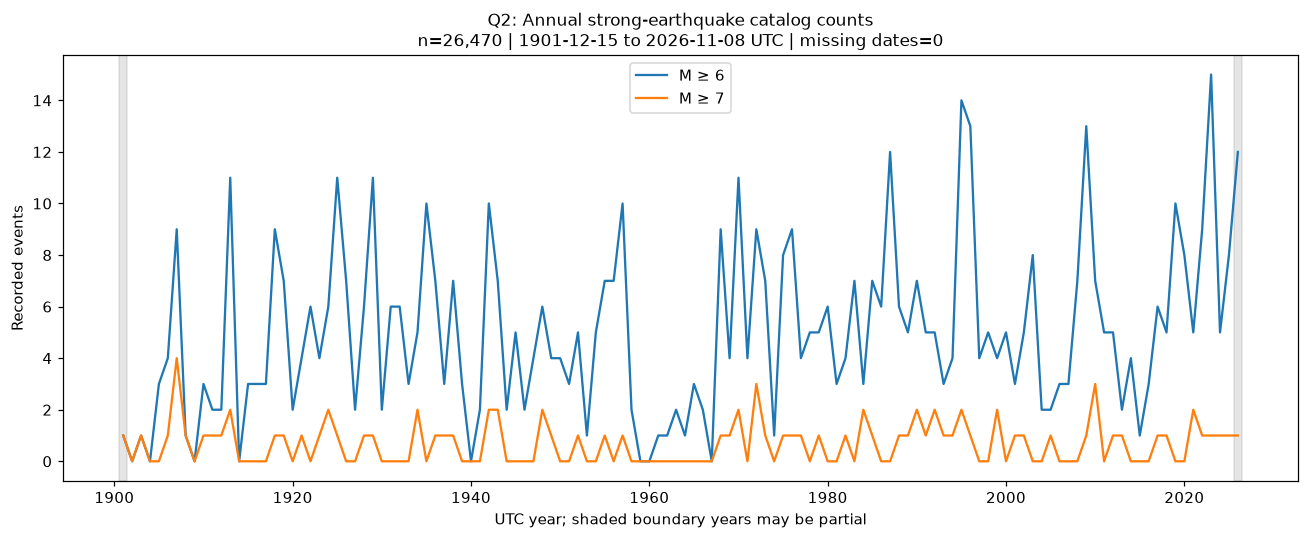

Complete interior-year comparisons (catalog completeness is not assumed):


,M ≥ 6,M ≥ 7
count,124.000000,124.000000
mean,4.967742,0.669355
std,3.290626,0.793487
min,0.000000,0.000000
25%,3.000000,0.000000
50%,5.000000,1.000000
75%,7.000000,1.000000
max,15.000000,4.000000


In [15]:
if df_frequency.empty:
    print("No dated magnitude records are available.")
else:
    dated = df["time"].dropna()
    years = pd.Index(range(dated.dt.year.min(), dated.dt.year.max()+1), name="year")
    annual_counts = pd.DataFrame(index=years)
    for threshold in [STRONG_MAG, VERY_STRONG_MAG]:
        selected = df_frequency.loc[df_frequency["mag"].ge(threshold)]
        annual_counts[f"M ≥ {threshold:g}"] = selected.groupby("year").size().reindex(years, fill_value=0)
        assert annual_counts[f"M ≥ {threshold:g}"].sum() == len(selected)
    annual_counts["potentially_partial"] = annual_counts.index.isin([years.min(), years.max()])
    display(annual_counts)

    fig, ax = plt.subplots(figsize=(12, 5))
    annual_counts.drop(columns="potentially_partial").plot(ax=ax, linewidth=1.5)
    for year in sorted(set([years.min(), years.max()])):
        ax.axvspan(year-0.45,year+0.45,color="gray",alpha=0.2)
    ax.set_title("Q2: Annual strong-earthquake catalog counts\n" + coverage(df_frequency))
    ax.set_xlabel("UTC year; shaded boundary years may be partial")
    ax.set_ylabel("Recorded events")
    save_plot(fig, "q2_annual_counts")
    print("Complete interior-year comparisons (catalog completeness is not assumed):")
    display(annual_counts.loc[~annual_counts.potentially_partial].drop(columns="potentially_partial").describe())


### Q3 Depth and magnitude

**Question:** How are magnitude and depth distributed and associated?

**How to read:** Histograms show distributions, the pie summarizes depth bands, and the scatter shows paired records. Spearman rho near zero indicates weak overall monotonic association.

**Observation:** [Report correlation comparisons, frequent depths, and sensitivity to zero magnitude and magnitude type.]

**Meaning and limitation:** Repeated depths and unresolved zeros need source review. Correlation does not identify a physical mechanism.


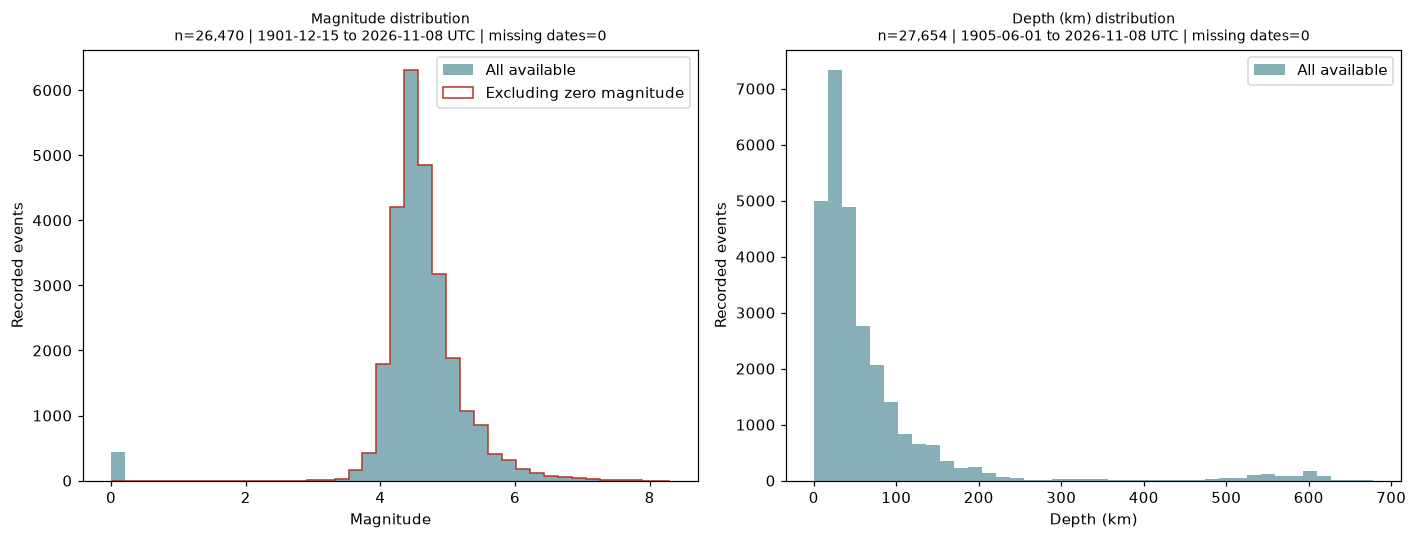

,mag,depth
count,26470.000000,27654.000000
mean,4.572465,69.811276
std,0.774878,99.680590
min,0.000000,0.700000
25%,4.300000,33.000000
50%,4.500000,35.000000
75%,4.800000,73.900000
max,8.300000,678.000000


Exact 10 km depths: 3904


depth
33.0     5548
10.0     3904
35.0     2100
15.0      319
100.0     195
25.0      103
50.0       86
150.0      62
200.0      62
60.0       59
Name: records, dtype: int64

Missing depths: 2 Negative depths: 0


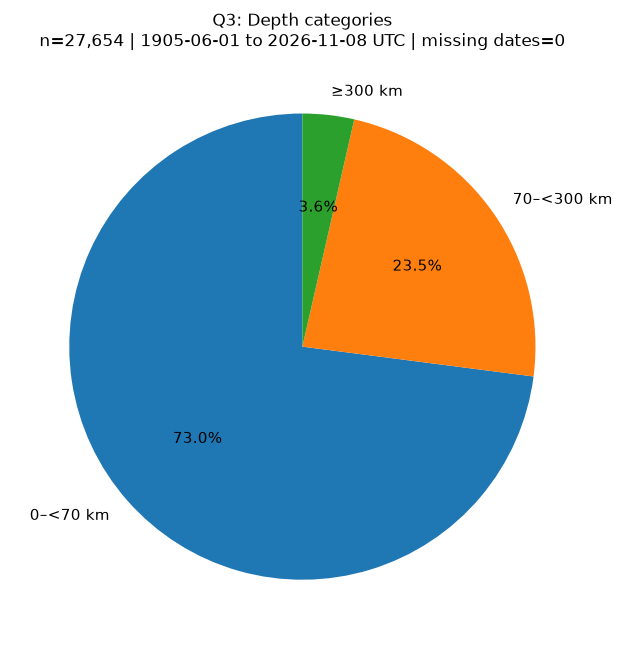

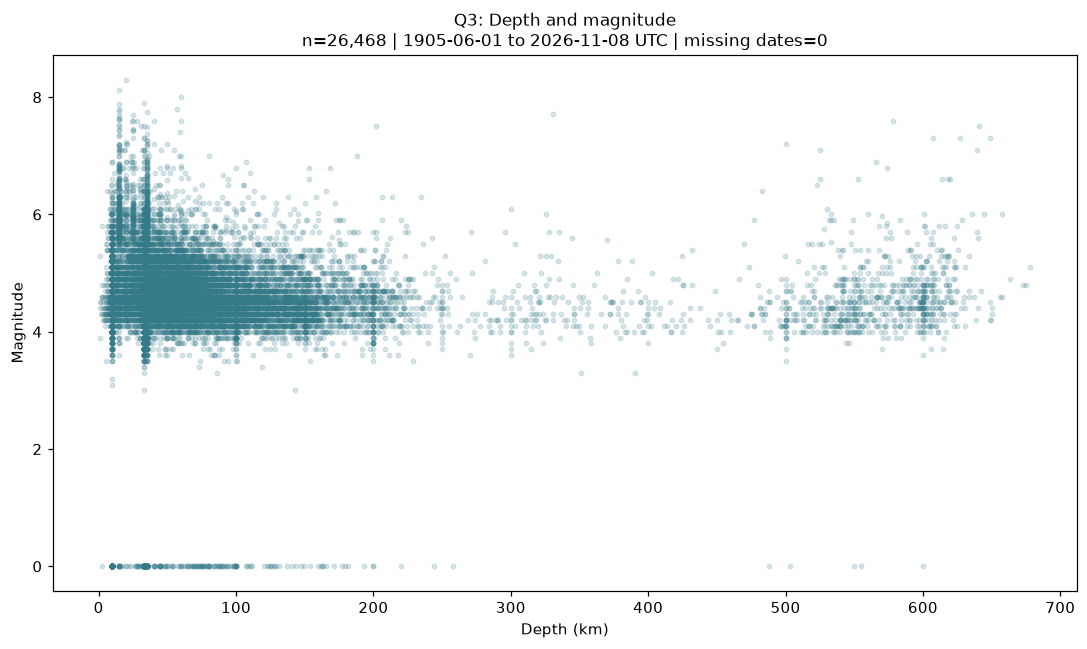

,subset,n,Spearman rho
0,All paired records,26468,-0.046910
1,Excluding zero magnitude,26023,-0.056636
2,Most common type: mb,23191,-0.026192


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for column, label, ax in zip(["mag", "depth"], ["Magnitude", "Depth (km)"], axes):
    available = df.dropna(subset=[column])
    ax.hist(available[column], bins=40, color="#357a89", alpha=0.6, label="All available")
    if column == "mag":
        ax.hist(available.loc[available.mag.ne(0), column], bins=np.histogram_bin_edges(available[column], bins=40), histtype="step", color="#b53627", label="Excluding zero magnitude")
    ax.set_title(label + " distribution\n" + coverage(available), fontsize=9)
    ax.set_xlabel(label); ax.set_ylabel("Recorded events"); ax.legend()
save_plot(fig, "q3_distributions")
display(df[["mag", "depth"]].describe())
print("Exact 10 km depths:", int(df.depth.eq(10).sum()))
display(df.depth.value_counts().head(10).rename("records"))

eligible_depth = df.loc[df.depth.ge(0)].copy()
categories = pd.cut(eligible_depth.depth, bins=[0,70,300,np.inf], right=False, labels=["0–<70 km", "70–<300 km", "≥300 km"])
depth_counts = categories.value_counts(sort=False)
assert depth_counts.sum() == len(eligible_depth)
print("Missing depths:", df.depth.isna().sum(), "Negative depths:", df.depth.lt(0).sum())
if len(eligible_depth):
    fig, ax = plt.subplots(figsize=(8, 6))
    nonempty = depth_counts.loc[depth_counts.gt(0)]
    ax.pie(nonempty, labels=nonempty.index, autopct="%1.1f%%", startangle=90)
    ax.set_title("Q3: Depth categories\n" + coverage(eligible_depth))
    save_plot(fig, "q3_depth_categories")

pairs = df_depth_mag.copy()
if len(pairs):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(pairs.depth, pairs.mag, s=8, alpha=0.18, color="#357a89")
    ax.set_xlabel("Depth (km)"); ax.set_ylabel("Magnitude")
    ax.set_title("Q3: Depth and magnitude\n" + coverage(pairs))
    save_plot(fig, "q3_depth_magnitude")
    def spearman(frame):
        return frame[["depth", "mag"]].rank().corr().loc["depth", "mag"] if len(frame) >= 3 else np.nan
    types = pairs.magType.dropna().value_counts()
    comparisons = {"All paired records": pairs, "Excluding zero magnitude": pairs.loc[pairs.mag.ne(0)]}
    if len(types):
        common_type = types.index[0]
        comparisons[f"Most common type: {common_type}"] = pairs.loc[pairs.magType.eq(common_type)]
    display(pd.DataFrame([{"subset":name,"n":len(frame),"Spearman rho":spearman(frame)} for name,frame in comparisons.items()]))


### Q4 Tsunami-flagged records and surrounding seas

**Question:** Where are flagged events located relative to all mapped earthquakes?

**How to read:** Panels share extent and marker size. The second includes only tsunami == 1; sea labels provide orientation.

**Observation:** [Report flagged count, date coverage, and visible geographic concentrations.]

**Meaning and limitation:** The flag does not confirm a tsunami; oceanic location is partly built into its interpretation. Missing earlier flags do not establish absence of historical tsunamis. Felt-report/significance analysis remains deferred.


tsunami
0    27621
1       35
Name: count, dtype: int64

,subset,records,missing_time,earliest,latest
0,All mapped,27656,0,1901-12-15 06:57:00.000+00:00,2026-11-08 07:25:35.852+00:00
1,Flag = 1,35,0,2013-10-15 08:12:32.050+00:00,2026-01-10 22:58:23.726+00:00


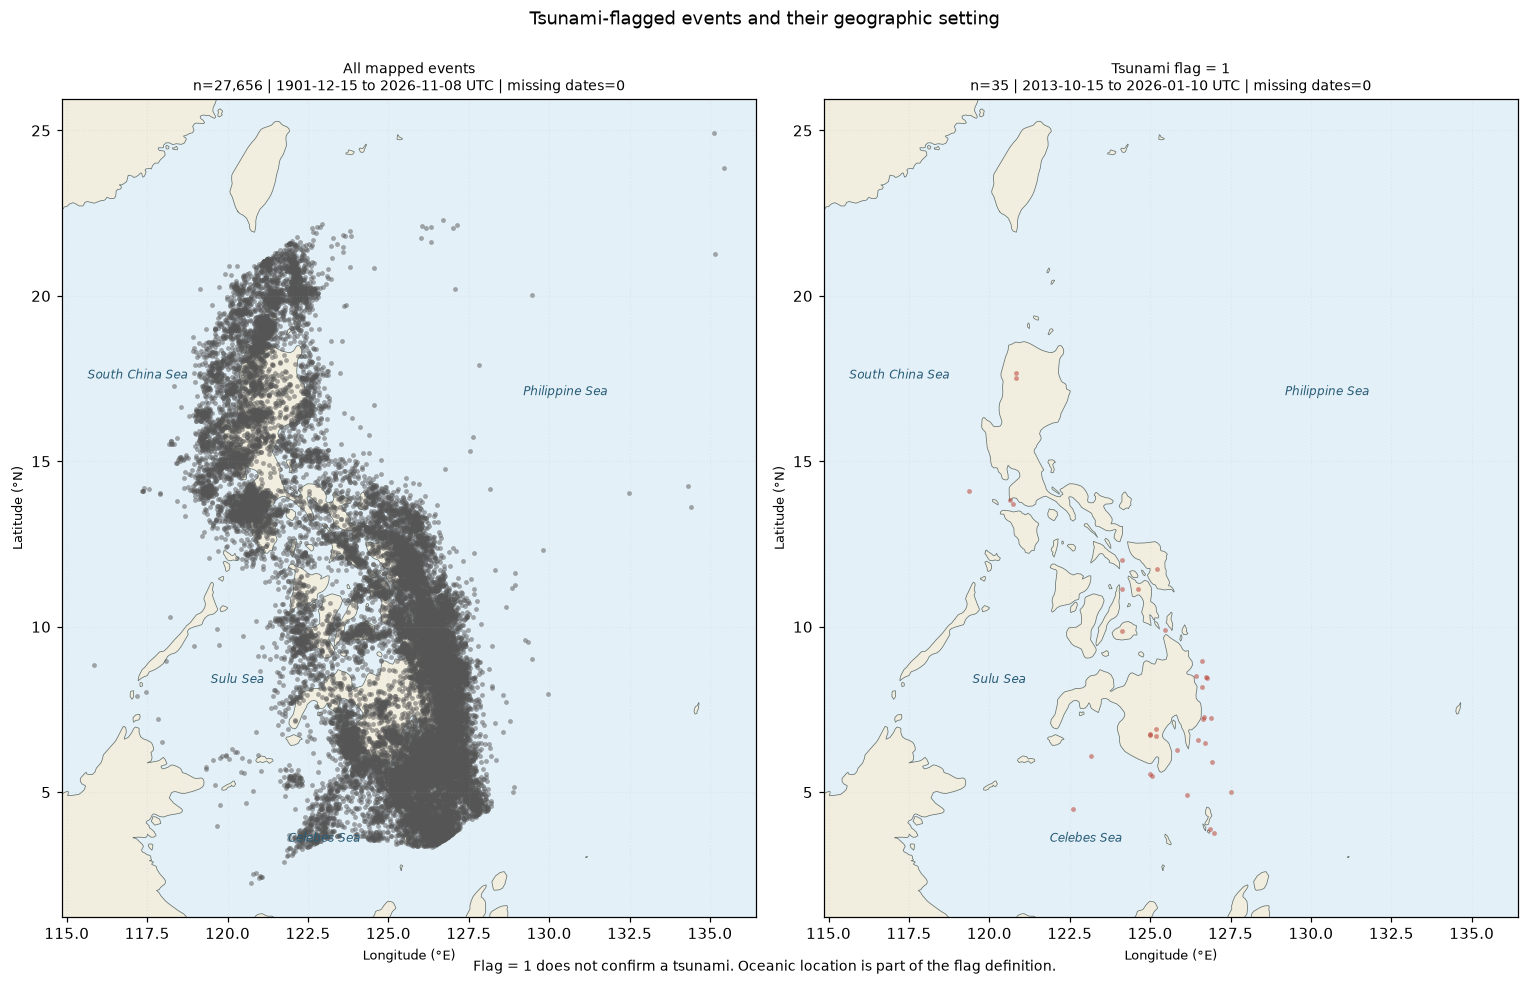

In [17]:
display(df.tsunami.value_counts(dropna=False))
flagged = df_tsunami.loc[df_tsunami.tsunami.eq(1)]
display(pd.DataFrame([{"subset":name,"records":len(frame),"missing_time":frame.time.isna().sum(),
                      "earliest":frame.time.min(),"latest":frame.time.max()}
                     for name,frame in [("All mapped",df_tsunami),("Flag = 1",flagged)]]))

fig, axes = plt.subplots(1, 2, figsize=(14, 9))
for ax, frame, title, color in zip(axes,[df_tsunami,flagged],
                                  ["All mapped events","Tsunami flag = 1"],["#555555","#b53627"]):
    map_base(ax, bounds)
    ax.scatter(frame.longitude,frame.latitude,s=10,color=color,alpha=0.5,linewidths=0)
    for label,lon,lat in [("South China Sea",117.2,17.5),("Philippine Sea",130.5,17),
                          ("Sulu Sea",120.3,8.3),("Celebes Sea",123,3.5)]:
        if bounds[0]<lon<bounds[2] and bounds[1]<lat<bounds[3] and not land.empty:
            ax.text(lon,lat,label,fontsize=8,color="#285c78",ha="center",style="italic")
    ax.set_title(title+"\n"+coverage(frame),fontsize=9)
    if frame.empty:
        ax.text(0.5,0.5,"No flagged events",transform=ax.transAxes,ha="center")
fig.suptitle("Tsunami-flagged events and their geographic setting")
fig.text(0.5,0.01,"Flag = 1 does not confirm a tsunami. Oceanic location is part of the flag definition.",ha="center",fontsize=9)
fig.tight_layout(rect=[0,0.04,1,0.95])
fig.savefig(output_dir/"earthquakes_tsunami_map.png",dpi=200,bbox_inches="tight")
plt.show()


## Methods and limitations in brief

- All geographic figures use the same valid-coordinate records, including nearby and offshore events. Historical catalog coverage varies.
- Grid boundaries are analytical choices; heatmap colors depend on smoothing and zoom. Neither measures damage risk.
- Same-ID latest-update handling does not resolve every potential different-ID duplicate.
- Zero magnitudes remain unresolved; retain the existing comparisons. Repeated depths and mixed magnitude types affect interpretation.
- Tectonic lines are incomplete provisional third-party geometry. Proximity does not identify an earthquake's source fault.
- Tsunami and impact fields have restricted reporting coverage. Felt-report analysis remains deferred.

## 2.4.2 Insights and conclusion

[Write your own answers to Q1–Q4 from the figures and tables. For each, give an observation, evidence, meaning, and main limitation.]


<a id="ml-extension"></a>

## ML extension — Do similar earthquakes occur in similar places?

The descriptive maps establish where earthquakes were recorded. This experiment asks whether magnitude and depth supply useful profiles, then returns those profiles to the map. Coordinates and tectonic lines do not determine the profiles.

**Story sequence:** look beneath the map → return to geography → challenge the result. GMM groups describe this selected catalog; they do not establish physical mechanisms, source faults, future activity, or hazard. You will write the interpretation after reviewing the figures.

In [16]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
import warnings

GMM_SEED = 42
GMM_COMPONENTS = range(1, 6)
PROFILE_COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#332288"]
DEPTH_LABELS = ["0–<70 km", "70–<300 km", "≥300 km"]

def prepare_profiles(frame):
    selected = frame.copy()
    audit = [{"step": "Cleaned catalog", "retained": len(selected), "excluded_at_step": 0}]
    rules = [
        ("Valid coordinates", lambda d: np.isfinite(d.latitude) & np.isfinite(d.longitude) & d.latitude.between(-90,90) & d.longitude.between(-180,180)),
        ("Finite positive magnitude", lambda d: np.isfinite(d.mag) & d.mag.gt(0)),
        ("Finite nonnegative depth", lambda d: np.isfinite(d.depth) & d.depth.ge(0)),
        ("Reported magnitude type", lambda d: d.magType.notna() & d.magType.astype(str).str.strip().ne("")),
    ]
    for name, rule in rules:
        previous = len(selected)
        selected = selected.loc[rule(selected)].copy()
        audit.append({"step": name, "retained": len(selected), "excluded_at_step": previous-len(selected)})
    counts = selected.magType.value_counts()
    common = sorted(counts.index[counts.eq(counts.max())])[0] if len(counts) else None
    previous = len(selected)
    selected = selected.loc[selected.magType.eq(common)].copy() if common is not None else selected.iloc[:0].copy()
    audit.append({"step": f"Most common eligible magnitude type: {common}", "retained": len(selected), "excluded_at_step": previous-len(selected)})
    audit = pd.DataFrame(audit)
    assert audit.excluded_at_step.sum() + len(selected) == len(frame)
    return selected, audit, common

def profile_features(frame, log_depth=True):
    # Geographic information is deliberately absent from the fitted features.
    values = frame[["mag", "depth"]].to_numpy(dtype=float).copy()
    if log_depth:
        values[:, 1] = np.log1p(values[:, 1])
    scaler = StandardScaler()
    return scaler.fit_transform(values), scaler

def fit_profiles(frame, variant, log_depth=True):
    rows, fitted = [], {}
    if len(frame) < 20 or frame[["mag","depth"]].nunique().lt(2).any():
        return pd.DataFrame([{"variant":variant,"components":0,"n_events":len(frame),"valid":False,"status":"Insufficient observations or feature variation"}]), None, None
    X, scaler = profile_features(frame, log_depth)
    for k in GMM_COMPONENTS:
        row = {"variant":variant,"components":k,"n_events":len(frame),"valid":False}
        if len(np.unique(X,axis=0)) < k:
            row["status"] = "Fewer distinct feature pairs than components"
            rows.append(row)
            continue
        try:
            with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
                warnings.simplefilter("always", ConvergenceWarning)
                model = GaussianMixture(n_components=k,covariance_type="full",n_init=10,
                    random_state=GMM_SEED,reg_covar=1e-4,max_iter=500).fit(X)
            bic = model.bic(X)
            valid = bool(model.converged_ and np.isfinite(bic))
            row.update(bic=bic,converged=bool(model.converged_),iterations=int(model.n_iter_),
                       valid=valid,status="Converged" if valid else "Nonconverged or nonfinite BIC",
                       warnings="; ".join(str(w.message) for w in caught))
            if valid: fitted[k] = model
        except (ValueError, np.linalg.LinAlgError) as error:
            row["status"] = str(error)
        rows.append(row)
    table = pd.DataFrame(rows)
    valid_rows = table.loc[table.valid]
    if valid_rows.empty: return table, None, scaler
    best_k = int(valid_rows.sort_values(["bic","components"]).iloc[0].components)
    table["selected"] = table.components.eq(best_k) & table.valid
    return table, fitted[best_k], scaler

### 1. Look beneath the map

**Question:** Are there useful magnitude–depth profiles within one reported magnitude scale?

**How to read:** Colors identify model profiles. The axes remain in original units; the model uses standardized magnitude and log-transformed depth. Profile numbers are ordered by median depth. The table describes each profile and its within-model membership certainty.

**Observation:** [Describe the actual profiles, their overlap, and their sizes. Do not name them before inspecting the output.]

**Meaning and limitation:** A Gaussian mixture is a statistical approximation. One component is an allowed result. If five wins, it is the best within the tested 1–5 range, not proof of five natural types. Membership certainty refers to this model, and repeated catalog depths may influence the grouping. [GMM method](https://scikit-learn.org/stable/modules/mixture.html).

,step,retained,excluded_at_step
0,Cleaned catalog,27656,0
1,Valid coordinates,27656,0
2,Finite positive magnitude,26025,1631
3,Finite nonnegative depth,26023,2
4,Reported magnitude type,26023,0
5,Most common eligible magnitude type: mb,23191,2832


ML subset: magnitude type=mb | n=23,191 | 1973-01-02 to 2026-11-08 UTC | missing dates=0


,variant,components,n_events,valid,bic,converged,iterations,status,warnings,selected
0,Primary: standardized magnitude + log1p depth,1,23191,True,131668.776862,True,2,Converged,,False
1,Primary: standardized magnitude + log1p depth,2,23191,True,130671.041146,True,11,Converged,,False
2,Primary: standardized magnitude + log1p depth,3,23191,True,88690.620609,True,28,Converged,,False
3,Primary: standardized magnitude + log1p depth,4,23191,True,87179.103258,True,20,Converged,,False
4,Primary: standardized magnitude + log1p depth,5,23191,True,85055.989287,True,15,Converged,,True


,records,median_magnitude,median_depth_km,depth_q25_km,depth_q75_km,median_membership_certainty,share,mixture_weight
profile,,,,,,,,
1,3596,4.5,10.000,10.0000,10.000,0.998285,0.155060,0.154481
2,6668,4.5,33.000,33.0000,35.000,0.941935,0.287525,0.266756
3,4006,4.9,44.667,25.0025,69.175,0.796913,0.172739,0.240491
4,8200,4.4,78.697,58.5000,113.810,0.766731,0.353585,0.307398
5,721,4.4,568.000,537.5000,600.000,0.994226,0.031090,0.030874


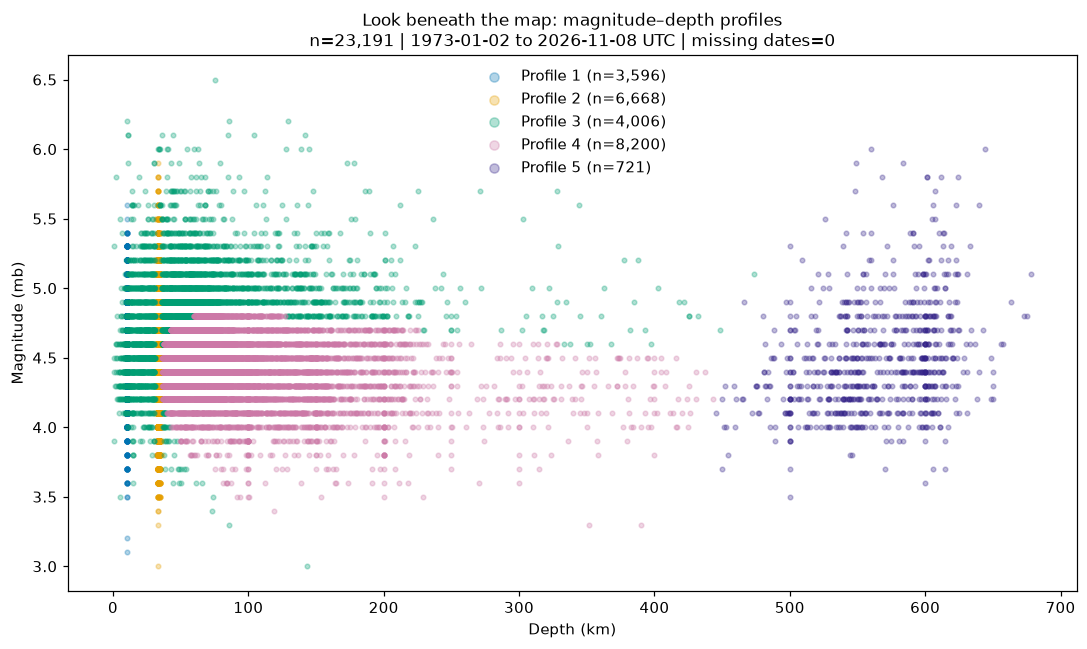

Selected 5 component(s). Labels describe statistical profiles; review overlap before interpreting.
The selected count is the upper boundary of the tested range (1–5), not evidence of five natural earthquake types.


In [19]:
ml_profiles, profile_audit, profile_mag_type = prepare_profiles(df)
display(profile_audit)
profile_audit.to_csv(output_dir/"ml_profile_subset_audit.csv",index=False)
print(f"ML subset: magnitude type={profile_mag_type} | {coverage(ml_profiles)}")
profile_fits, profile_model, profile_scaler = fit_profiles(ml_profiles,"Primary: standardized magnitude + log1p depth")
profile_fits.to_csv(output_dir/"ml_profile_model_selection.csv",index=False)
display(profile_fits)
if profile_model is None:
    print("GMM skipped: insufficient data or no valid converged model. See selection table.")
else:
    X, _ = profile_features(ml_profiles)
    raw_labels = profile_model.predict(X)
    probabilities = profile_model.predict_proba(X)
    ml_profiles["raw_component"] = raw_labels
    order = sorted(range(profile_model.n_components),key=lambda j: (
        ml_profiles.loc[ml_profiles.raw_component.eq(j),"depth"].median()
        if np.any(raw_labels==j) else np.inf, j))
    label_map = {raw: index+1 for index,raw in enumerate(order)}
    ml_profiles["profile"] = [label_map[j] for j in raw_labels]
    ml_profiles["membership_certainty"] = probabilities.max(axis=1)
    for raw in order:
        ml_profiles[f"probability_profile_{label_map[raw]}"] = probabilities[:,raw]
    ml_profiles["depth_category"] = pd.cut(ml_profiles.depth,bins=[0,70,300,np.inf],right=False,labels=DEPTH_LABELS)
    profile_summary = ml_profiles.groupby("profile").agg(records=("id","size"),
        median_magnitude=("mag","median"),median_depth_km=("depth","median"),
        depth_q25_km=("depth",lambda s:s.quantile(.25)),depth_q75_km=("depth",lambda s:s.quantile(.75)),
        median_membership_certainty=("membership_certainty","median"))
    profile_summary["share"] = profile_summary.records/len(ml_profiles)
    profile_summary["mixture_weight"] = [profile_model.weights_[order[i-1]] for i in profile_summary.index]
    display(profile_summary)
    assert profile_summary.records.sum()==len(ml_profiles)
    assert np.allclose(probabilities.sum(axis=1),1)
    ml_profiles.to_csv(output_dir/"ml_profile_memberships.csv",index=False)
    profile_summary.to_csv(output_dir/"ml_profile_summary.csv")
    fig,ax=plt.subplots(figsize=(10,6))
    for label,group in ml_profiles.groupby("profile"):
        ax.scatter(group.depth,group.mag,s=9,alpha=.3,color=PROFILE_COLORS[label-1],
                   label=f"Profile {label} (n={len(group):,})",rasterized=True)
    ax.set(xlabel="Depth (km)",ylabel=f"Magnitude ({profile_mag_type})",title="Look beneath the map: magnitude–depth profiles\n"+coverage(ml_profiles))
    ax.legend(frameon=False,markerscale=2)
    save_plot(fig,"ml_profile_characteristics")
    print(f"Selected {profile_model.n_components} component(s). Labels describe statistical profiles; review overlap before interpreting.")
    if profile_model.n_components == max(GMM_COMPONENTS):
        print("The selected count is the upper boundary of the tested range (1–5), not evidence of five natural earthquake types.")

### 2. Return to geography

**Question:** Where do the profiles occur, and what spatial relationships are visible beside the mapped tectonic features?

**How to read:** Profile colors match the magnitude–depth chart. Every panel has the same extent and marker styling. Panel counts show different sample sizes; dense points can overlap. The fault/trench reference is provisional and incomplete.

**Observation:** [Compare profile locations. Identify a visible relationship and an exception, if supported.]

**Meaning and limitation:** Coordinates were withheld from fitting, so geographic patterns are a subsequent descriptive comparison. Proximity to a mapped line does not establish the source fault or earthquake mechanism. These static maps also work when Folium cannot render.

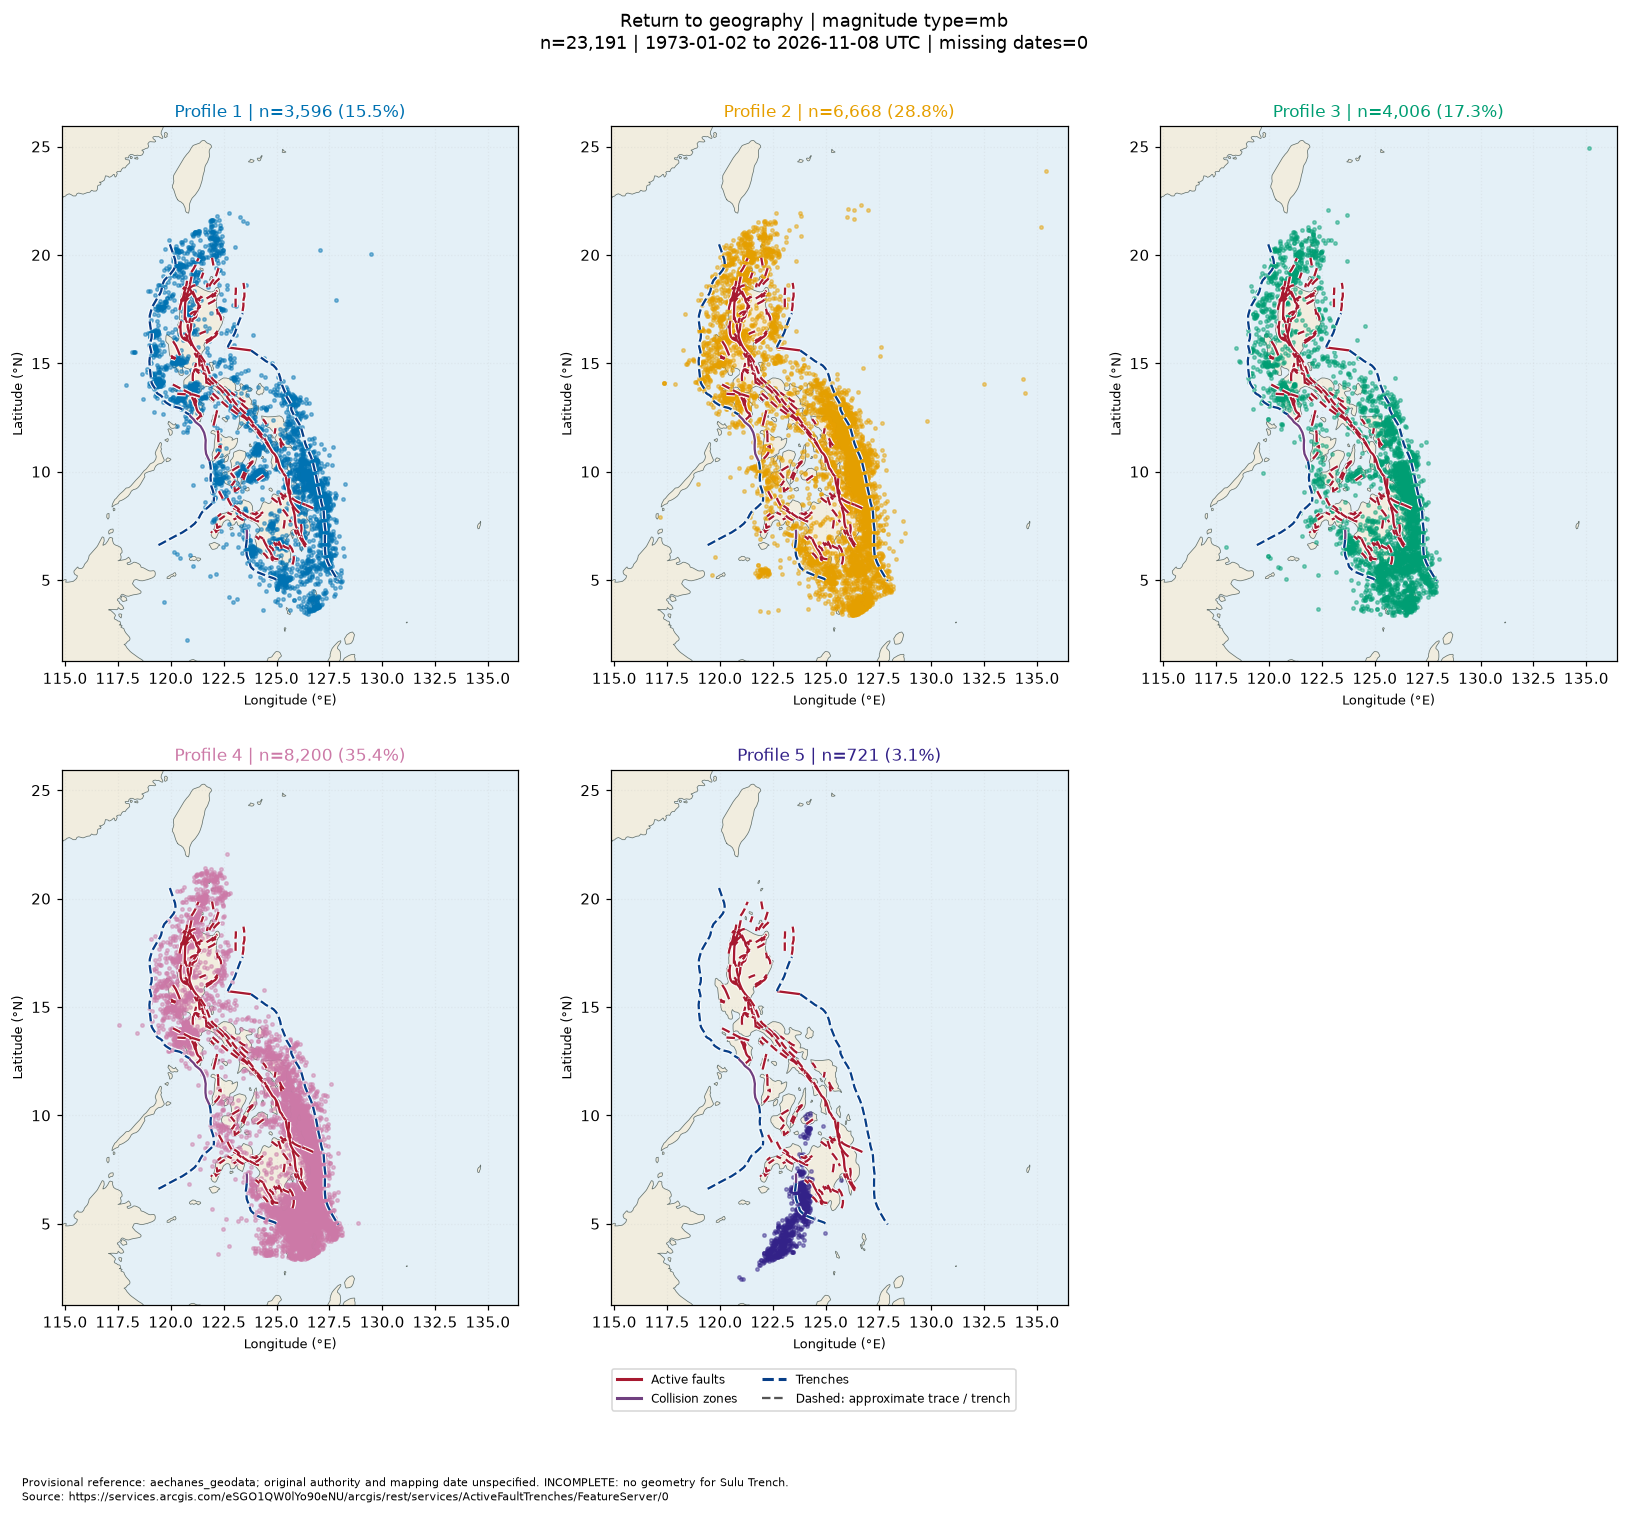

In [20]:
if profile_model is not None:
    count=profile_model.n_components
    columns=min(3,count)
    rows=int(np.ceil(count/columns))
    fig,axes=plt.subplots(rows,columns,figsize=(5*columns,6*rows),squeeze=False)
    for index,ax in enumerate(axes.flat):
        if index>=count:
            ax.set_visible(False)
            continue
        label=index+1
        group=ml_profiles.loc[ml_profiles.profile.eq(label)]
        map_base(ax,bounds)
        ax.scatter(group.longitude,group.latitude,s=5,alpha=.45,color=PROFILE_COLORS[index],rasterized=True,zorder=3)
        draw_tectonics(ax,bounds)
        ax.set_title(f"Profile {label} | n={len(group):,} ({len(group)/len(ml_profiles):.1%})",color=PROFILE_COLORS[index])
    if layers:
        fig.legend(handles=tectonic_handles(),loc="lower center",bbox_to_anchor=(.5,-.045),ncol=2,fontsize=8)
    fig.suptitle(f"Return to geography | magnitude type={profile_mag_type}\n"+coverage(ml_profiles),fontsize=12,y=1.02)
    tectonic_caption(fig)
    # Separate the provenance caption from the shared tectonic legend.
    fig.texts[-1].set_position((.02,-.09))
    fig.tight_layout(h_pad=4, w_pad=2)
    fig.savefig(output_dir/"ml_profile_geography.png",dpi=200,bbox_inches="tight")
    plt.show()

### 3. Challenge the result

**Question:** Does the model add useful information beyond ordinary depth categories, and does the grouping survive reasonable choices?

**How to read:** Each bar shows the profile composition of one existing depth category, using the same ML subset. The robustness table reports agreement with the primary grouping (ARI: 1 means identical assignments, near 0 means chance-level agreement). Five seeds repeat the chosen component count; alternative preprocessing variants select their own count. BIC is compared only within a variant.

**Observation:** [Does the grouping largely repeat depth categories? Is the main distinction stable across seeds, raw depth, and removal of exact 10/33 km depths?]

**Meaning and limitation:** Excluding repeated depths is a sensitivity check, not a claim that those records are wrong. Strong agreement supports reproducibility under these checks, not geological truth. If the profiles are unstable or redundant, conclude that ML adds limited descriptive value.

,check,n_events,selected_components,valid,agreement_ARI
0,Primary preprocessing; seed=0,23191,5,True,0.965001
1,Primary preprocessing; seed=7,23191,5,True,0.850836
2,Primary preprocessing; seed=21,23191,5,True,0.889902
3,Primary preprocessing; seed=42,23191,5,True,1.000000
4,Primary preprocessing; seed=99,23191,5,True,0.964585
5,Sensitivity: standardized raw depth,23191,5,True,0.209228
6,Sensitivity: exclude exact 10/33 km,15303,5,True,0.771324


profile,1,2,3,4,5
depth_category,,,,,
0–<70 km,3596,6668,3017,3282,0
70–<300 km,0,0,953,4792,0
≥300 km,0,0,36,126,721


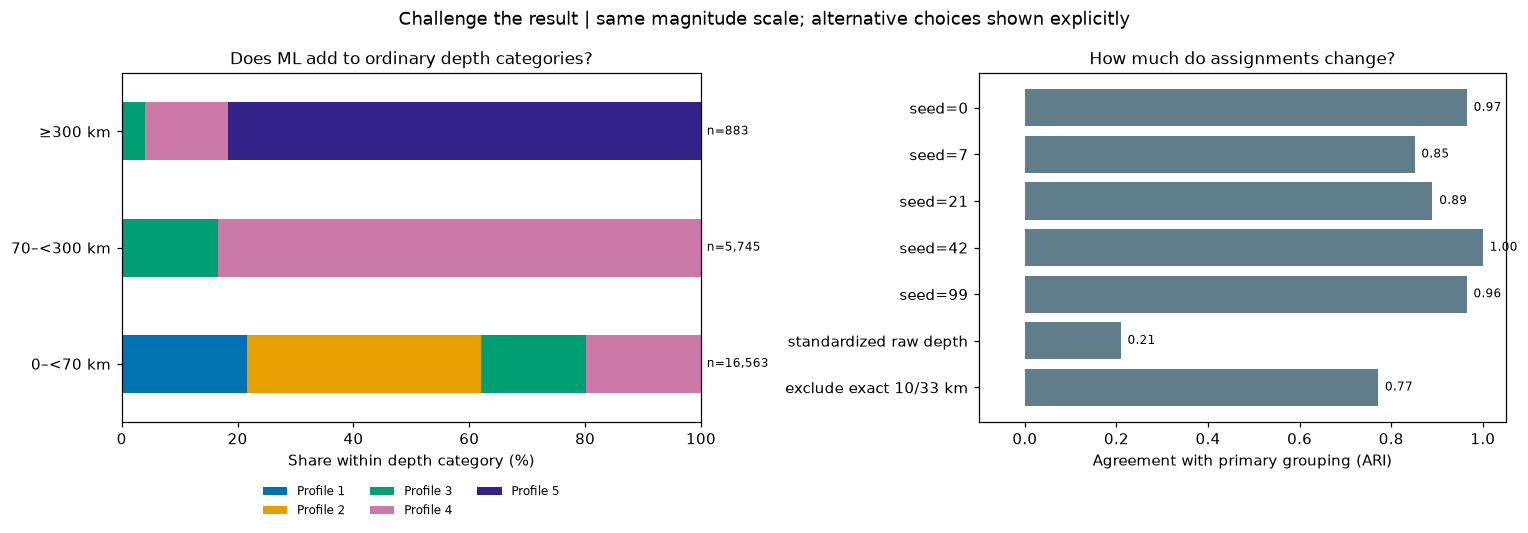

Depth-category/profile agreement (descriptive ARI): 0.145
Presentation prompt: choose one supported observation, explain its boundary, and decide whether ML adds enough value to retain in the main story.


In [21]:
if profile_model is not None:
    robustness=[]
    for seed in [0,7,21,42,99]:
        try:
            with warnings.catch_warnings(record=True), threadpool_limits(limits=1):
                candidate=GaussianMixture(n_components=profile_model.n_components,covariance_type="full",
                    n_init=10,random_state=seed,reg_covar=1e-4,max_iter=500).fit(X)
            valid=bool(candidate.converged_ and np.isfinite(candidate.bic(X)))
            robustness.append({"check":f"Primary preprocessing; seed={seed}","n_events":len(ml_profiles),
                "selected_components":candidate.n_components,"valid":valid,
                "agreement_ARI":adjusted_rand_score(raw_labels,candidate.predict(X)) if valid else np.nan})
        except (ValueError,np.linalg.LinAlgError) as error:
            robustness.append({"check":f"seed={seed}","valid":False,"status":str(error)})
    selections=[profile_fits]
    for name,subset,log_depth in [
        ("Sensitivity: standardized raw depth",ml_profiles,False),
        ("Sensitivity: exclude exact 10/33 km",ml_profiles.loc[~ml_profiles.depth.isin([10.,33.])].copy(),True)]:
        comparison,candidate,_=fit_profiles(subset,name,log_depth)
        selections.append(comparison)
        valid=candidate is not None
        transformed,_=profile_features(subset,log_depth) if valid else (None,None)
        robustness.append({"check":name,"n_events":len(subset),"selected_components":candidate.n_components if valid else np.nan,
            "valid":valid,"agreement_ARI":adjusted_rand_score(subset.raw_component,candidate.predict(transformed)) if valid else np.nan})
    robustness=pd.DataFrame(robustness)
    robustness.to_csv(output_dir/"ml_profile_robustness.csv",index=False)
    pd.concat(selections,ignore_index=True).to_csv(output_dir/"ml_profile_model_selection.csv",index=False)
    display(robustness)
    cross=pd.crosstab(ml_profiles.depth_category,ml_profiles.profile,dropna=False).reindex(index=DEPTH_LABELS,columns=range(1,profile_model.n_components+1),fill_value=0)
    assert cross.to_numpy().sum()==len(ml_profiles)
    cross.to_csv(output_dir/"ml_profile_depth_comparison.csv")
    display(cross)
    percentages=cross.div(cross.sum(axis=1).replace(0,np.nan),axis=0).fillna(0)*100
    fig,axes=plt.subplots(1,2,figsize=(14,5),gridspec_kw={"width_ratios":[1.1,1]})
    percentages.rename(columns=lambda j:f"Profile {j}").plot.barh(stacked=True,color=PROFILE_COLORS[:profile_model.n_components],ax=axes[0])
    axes[0].set(xlabel="Share within depth category (%)",ylabel="",xlim=(0,100),title="Does ML add to ordinary depth categories?")
    for i,total in enumerate(cross.sum(axis=1)):
        axes[0].text(101,i,f"n={total:,}",va="center",fontsize=8)
    axes[0].legend(frameon=False,fontsize=8,loc="upper center",bbox_to_anchor=(.5,-.15),ncol=3)
    valid_checks=robustness.loc[robustness.valid.eq(True)].iloc[::-1]
    short=[s.replace("Primary preprocessing; ","").replace("Sensitivity: ","") for s in valid_checks.check]
    axes[1].barh(short,valid_checks.agreement_ARI,color="#607d8b")
    axes[1].set(xlabel="Agreement with primary grouping (ARI)",xlim=(-.1,1.05),title="How much do assignments change?")
    for i,value in enumerate(valid_checks.agreement_ARI):
        axes[1].text(value+.015,i,f"{value:.2f}",va="center",fontsize=8)
    fig.suptitle("Challenge the result | same magnitude scale; alternative choices shown explicitly",fontsize=12)
    save_plot(fig,"ml_profile_challenge")
    print("Depth-category/profile agreement (descriptive ARI):",round(adjusted_rand_score(ml_profiles.depth_category.astype(str),ml_profiles.profile),3))
    print("Presentation prompt: choose one supported observation, explain its boundary, and decide whether ML adds enough value to retain in the main story.")

### Your presentation takeaway

[Write 2–3 sentences: what the profiles show; where the pattern appears geographically; whether the robustness checks support including it. A one-component result or limited additional value is acceptable.]

Detailed model-selection and robustness CSVs belong in the appendix. The existing coordinate-clustering experiment and anomaly review follow below.

## Appendix A — Optional ML experiments

The descriptive analysis stands independently. These experiments assess whether ML adds useful summaries of observed records. They do not forecast earthquakes or identify source faults.


In [22]:
from sklearn.cluster import DBSCAN
from sklearn.ensemble import IsolationForest


### A1 Does coordinate clustering add value beyond the maps?

**Question:** Does grouping nearby epicenters reveal useful geographic structure beyond the count and heat maps?

**How to read:** Distinct colors identify baseline groups; gray marks sparse records. DBSCAN connects dense neighborhoods, so a 25 km neighborhood is not the maximum cluster diameter. The table compares nine settings on the same geographic subset.

**Observation:** [Compare cluster count, largest-cluster share, and sparse share across settings. Identify anything that Q1 did not already communicate.]

**Meaning and limitation:** Clustering supplies irregular spatial groups and event memberships. If groups merge extensively or depend strongly on parameters, report limited additional descriptive value and retain the experiment only in this appendix. Do not tune for fault alignment.


,radius_km,min_samples,n_events,clusters,largest_cluster_share,sparse_share
0,15,10,27656,37,67.3%,6.9%
1,15,20,27656,50,62.1%,17.0%
2,15,40,27656,35,36.2%,34.2%
3,25,10,27656,6,98.0%,1.4%
4,25,20,27656,13,71.3%,4.0%
5,25,40,27656,21,66.1%,10.5%
6,40,10,27656,1,99.4%,0.6%
7,40,20,27656,2,99.0%,0.8%
8,40,40,27656,4,74.4%,2.2%


,records,median_magnitude,median_depth_km
cluster,,,
-1,1096,4.5,33.0000
0,19729,4.6,39.7185
1,4345,4.5,33.0000
2,1461,4.5,71.4000
3,262,4.6,35.0000
4,52,4.3,317.6500
5,449,4.6,33.0000
6,50,4.5,33.0000
7,36,4.9,35.2500


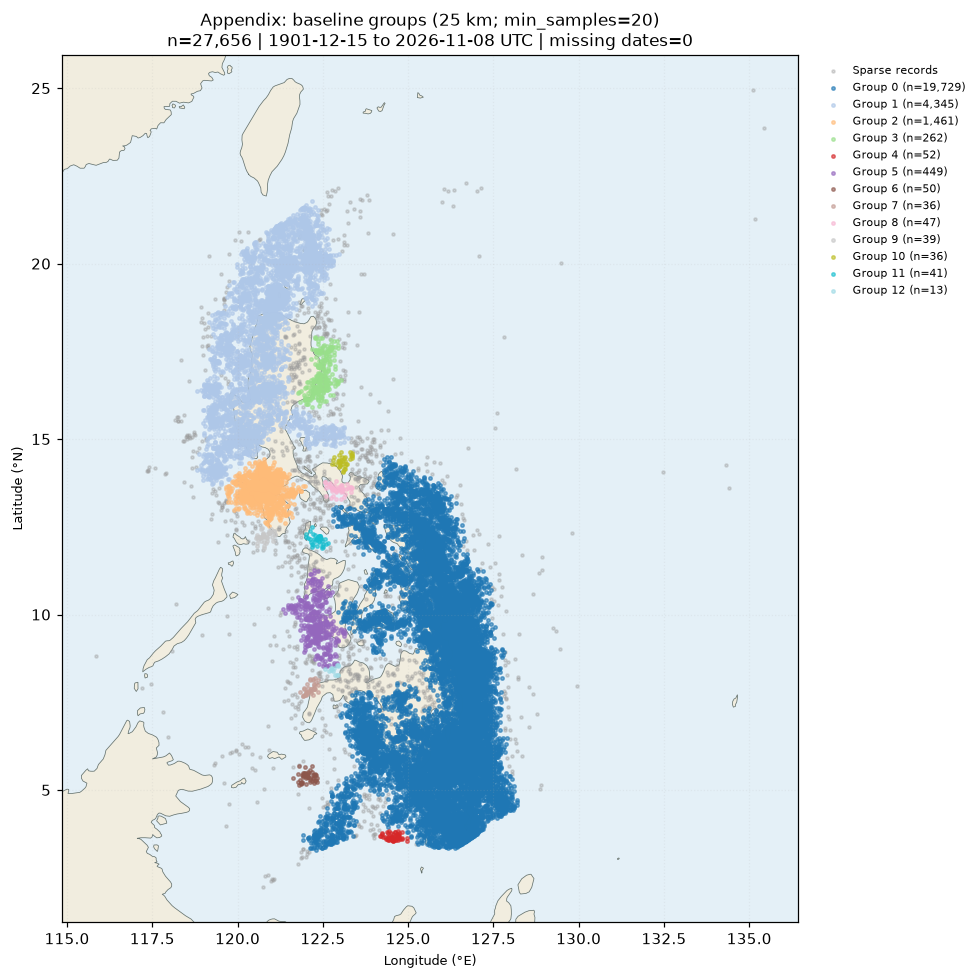

Interpretation prompt: compare the sensitivity table with Q1. Large merged groups or changing group sizes can indicate limited added value.


In [23]:
ml_geo=df_geo.copy()
RADIUS_KM,MIN_RECORDS=25,20
if ml_geo.empty:
    print("No valid coordinates; skip clustering.")
else:
    coords=np.radians(ml_geo[["latitude","longitude"]].to_numpy())
    rows=[]
    for radius in [15,25,40]:
        for minimum in [10,20,40]:
            labels=DBSCAN(eps=radius/6371.0088,min_samples=minimum,metric="haversine",algorithm="ball_tree").fit_predict(coords)
            sizes=pd.Series(labels[labels!=-1]).value_counts()
            rows.append({"radius_km":radius,"min_samples":minimum,"n_events":len(labels),"clusters":len(sizes),
                         "largest_cluster_share":sizes.max()/len(labels) if len(sizes) else 0.,"sparse_share":float(np.mean(labels==-1))})
            if (radius,minimum)==(RADIUS_KM,MIN_RECORDS):baseline=labels.copy()
    sensitivity=pd.DataFrame(rows)
    display(sensitivity.style.format({"largest_cluster_share":"{:.1%}","sparse_share":"{:.1%}"}))
    sensitivity.to_csv(output_dir/"ml_cluster_sensitivity.csv",index=False)
    ml_geo["cluster"]=baseline
    ml_geo.to_csv(output_dir/"ml_spatial_clusters.csv",index=False)
    summary=ml_geo.groupby("cluster").agg(records=("id","size"),median_magnitude=("mag","median"),median_depth_km=("depth","median"))
    display(summary)
    summary.to_csv(output_dir/"ml_cluster_summary.csv")
    fig,ax=plt.subplots(figsize=(10,9))
    map_base(ax,bounds)
    sparse=ml_geo.loc[ml_geo.cluster.eq(-1)]
    ax.scatter(sparse.longitude,sparse.latitude,s=4,c="#999999",alpha=.35,label="Sparse records")
    identifiers=sorted(ml_geo.loc[ml_geo.cluster.ne(-1),"cluster"].unique())
    palette=plt.get_cmap("tab20",max(1,len(identifiers)))
    for index,label in enumerate(identifiers):
        group=ml_geo.loc[ml_geo.cluster.eq(label)]
        ax.scatter(group.longitude,group.latitude,s=5,color=palette(index),alpha=.6,label=f"Group {label} (n={len(group):,})")
    ax.legend(fontsize=7,loc="upper left",bbox_to_anchor=(1.02,1),frameon=False)
    ax.set_title("Appendix: baseline groups (25 km; min_samples=20)\n"+coverage(ml_geo))
    save_plot(fig,"ml_spatial_clusters")
    if not identifiers:print("All records were marked sparse; no baseline groups found.")
    print("Interpretation prompt: compare the sensitivity table with Q1. Large merged groups or changing group sizes can indicate limited added value.")


### A2 Optional: Unusual magnitude–depth records

Use [Isolation Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html) to rank unusual magnitude–depth combinations for review. Restrict to the most common reported magnitude type, nonnegative depths, and positive magnitudes; zero magnitudes remain unresolved in this catalog. Higher scores mean more unusual combinations relative to this subset. The top ten are a review list, not confirmed errors; retain all original records. No accuracy claim is possible without verified anomaly labels.


,id,time,mag,depth,magType,unusual_score
25047,usp0001fp1,1981-09-04 19:15:13.610+00:00,6.0,644.5,mb,0.784885
24996,usp0001ghc,1981-10-18 04:04:15.420+00:00,5.8,624.6,mb,0.779593
11718,usp000hgmj,2010-07-24 06:57:40.640+00:00,5.8,611.5,mb,0.776434
20349,usp0007chf,1996-02-08 05:27:46.530+00:00,5.7,607.2,mb,0.775909
12011,usp000h2c2,2009-10-04 19:04:07.980+00:00,5.6,640.0,mb,0.772243
11717,usp000hgmk,2010-07-24 06:59:48.930+00:00,5.8,601.7,mb,0.771199
25930,usp0000rmz,1977-11-21 19:39:40.100+00:00,5.8,601.0,mb,0.771199
26633,usp0000a09,1975-02-23 10:58:41.000+00:00,5.6,623.0,mb,0.771199
25699,usp000101w,1979-04-16 06:14:52.500+00:00,5.9,549.0,mb,0.769114
26420,usp0000dv8,1975-12-09 09:23:26.900+00:00,5.7,548.0,mb,0.768594


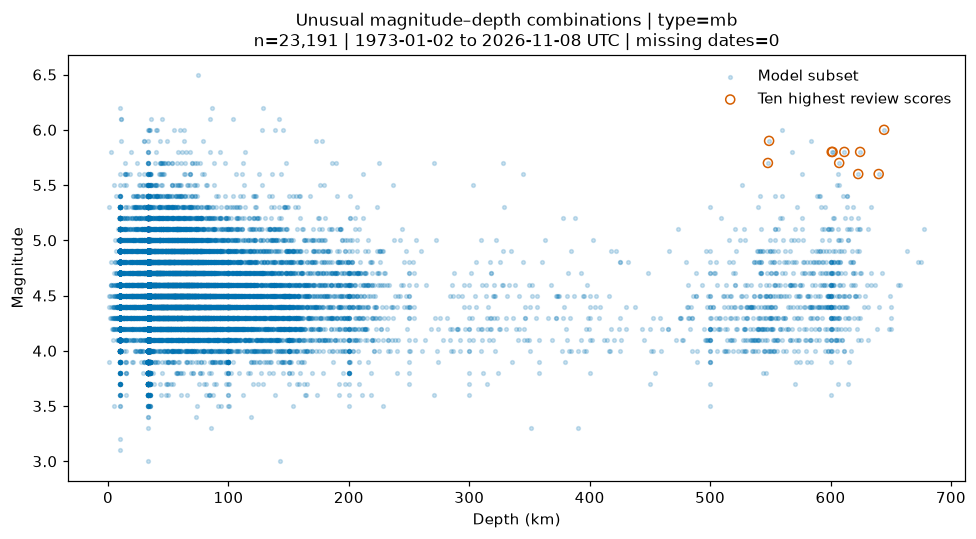

In [24]:
ml_review = df_depth_mag.loc[df_depth_mag.mag.gt(0) & df_depth_mag.depth.ge(0)].copy()
types = ml_review.magType.value_counts()
if types.empty:
    print("No reported magnitude types available; skip anomaly ranking.")
else:
    common_type = types.index[0]
    ml_review = ml_review.loc[ml_review.magType.eq(common_type)].copy()
    features = ml_review[["depth", "mag"]]
    if len(features) < 20 or features.nunique().le(1).all():
        print("Insufficient observations or variation for anomaly ranking.")
    else:
        model = IsolationForest(random_state=42, n_estimators=100)
        model.fit(features)
        ml_review["unusual_score"] = -model.score_samples(features)
        review = ml_review.nlargest(10, "unusual_score")
        display(review[["id", "time", "mag", "depth", "magType", "unusual_score"]])
        ml_review.to_csv(output_dir / "ml_unusual_scores.csv", index=False)
        review.to_csv(output_dir / "ml_review_top10.csv", index=False)

        fig, ax = plt.subplots(figsize=(9, 5))
        ax.scatter(ml_review.depth, ml_review.mag, s=6, alpha=0.2,
                   color="#0072B2", label="Model subset")
        ax.scatter(review.depth, review.mag, s=35, facecolors="none",
                   edgecolors="#D55E00", label="Ten highest review scores")
        ax.set(xlabel="Depth (km)", ylabel="Magnitude",
               title=f"Unusual magnitude–depth combinations | type={common_type}\n" + coverage(ml_review))
        ax.legend(frameon=False)
        save_plot(fig, "ml_unusual_records")


### Appendix interpretation

[Explain whether clustering added useful structure beyond Q1, supported by the sensitivity table. Limited additional value is a valid result. Inspect unusual magnitude–depth records using their source information; high scores do not establish errors.]
